# 미니프로젝트: 앙상블 모델링 (Vibe Coding)

#### <목표>
Day 3에서 배운 **Random Forest, GBM, XGBoost, LightGBM, CatBoost**를 Day 2와 **동일한 제조 데이터셋**에 적용해 봅니다.

- Day 1에서의 EDA, 전처리를 복습해보고
- Day 2에서 배웠던 다중선형회귀·Ridge·Lasso·의사결정나무로 만든 결과와 비교하면서
- Day 3에서 배운 앙상블 모델이 단일 모델 대비 어떤 성능 차이를 보이는지 확인해봅니다.

#### <데이터셋 소개>

**1) 회귀용 — Mining Process Flotation Plant (광물 선광 공정 데이터)**
- 철광석을 선광(flotation)하는 공정에서 1시간 간격으로 수집된 실제 산업 데이터
- 공정 변수로 최종 정광의 불순물(실리카) 비율을 예측

| 변수명 | 설명 |
|:---:|:---|
| date | 측정 일시 |
| % Iron Feed, % Silica Feed | 투입 원광의 철/실리카 품위 |
| Starch Flow, Amina Flow | 전분/아민 투입량 (시약) |
| Ore Pulp Flow, pH, Density | 광액 유량/산도/밀도 |
| Flotation Column 01~07 Air Flow | 플로테이션 컬럼별 공기 유량 |
| Flotation Column 01~07 Level | 플로테이션 컬럼별 액위 |
| % Iron Concentrate | 최종 정광의 철 비율 (실험실 측정) |
| **% Silica Concentrate** | **최종 정광의 실리카(불순물) 비율 — 회귀 타겟** |

**2) 분류용 — Steel Plates Faults (철강 표면 결함 검사 데이터)**
- 철강판 표면을 촬영해 측정한 결함의 위치/크기/광도 등으로 결함 유형을 분류하는 실제 품질검사 데이터

| 변수명 | 설명 |
|:---:|:---|
| X/Y_Minimum, X/Y_Maximum | 결함의 위치 범위 |
| Pixels_Areas, X/Y_Perimeter | 결함의 면적·둘레 |
| Sum/Minimum/Maximum_of_Luminosity | 결함 부위의 광도 |
| Length_of_Conveyer, Steel_Plate_Thickness | 설비/소재 정보 |
| TypeOfSteel_A300, TypeOfSteel_A400 | 철강 타입 |
| Edges_Index, Square_Index, Luminosity_Index 등 | 결함 형태 특징 지수 |
| Pastry, Z_Scratch, K_Scatch, Stains, Dirtiness, Bumps, Other_Faults | 결함 유형 |
| **K_Scatch** | **긴 스크래치성 결함 여부 — 분류 타겟** |

#### <실습 태스크>
| 태스크 | 데이터 파일 | 타겟 변수 | 사용 모델 |
|:---:|:---:|:---:|:---|
| 회귀 | `dataset/day2_miniproject_reg.csv` | `% Silica Concentrate` | Random Forest, GBM, XGBoost, LightGBM, CatBoost (회귀) |
| 분류 | `dataset/day2_miniproject_cls.csv` | `K_Scatch` | Random Forest, GBM, XGBoost, LightGBM, CatBoost (분류) |

#### <진행 순서>
**Part A(회귀)** 를 데이터 불러오기 → 탐색 → 전처리 → 모델링 → 예측 → 고도화 → 결과 해석까지 **끝까지 완료한 뒤**, **Part B(분류)** 를 동일한 흐름으로 진행합니다.

1. 각 섹션의 **과제**를 읽고, 어떤 고민/결정이 필요한지 먼저 생각해 봅니다.
2. 빈 코드 셀을 클릭한 후 Cursor AI 채팅창을 엽니다.
3. 막막한 부분은 AI와 상의해서 방법을 정하고, 그 방법으로 프롬프트를 작성합니다.
4. 생성된 코드를 실행하고 결과를 확인합니다.

## 0) 분석 준비

**[과제]** 써니는 Day 2에서 사용한 회귀 및 분류 데이터셋에 다양한 트리 기반 앙상블 모델을 적용해 보려고 합니다. 분석 준비와 데이터 전처리뿐만 아니라, 앙상블 모델 구축 및 하이퍼파라미터 탐색에 필요한 라이브러리를 AI와 상의하여 선정하고 불러오는 코드를 작성해 보세요.

---
# Part A. 회귀 태스크 — Mining Process Flotation Plant

## A-0) 데이터 불러오기

**[과제]** 써니는 Day 2에서 사용했던 `dataset/day2_miniproject_reg.csv` 파일을 그대로 불러오려고 합니다. 적절한 변수명으로 데이터프레임을 만들어 보세요.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    r2_score, mean_squared_error, mean_absolute_error
)

# 시각화 기본 설정
sns.set_theme(style="whitegrid", font="Malgun Gothic")  # 한글 폰트 (없으면 기본 폰트 사용)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.unicode_minus"] = False

# 분류 성능 평가
def get_classscore(real, pred):
    print("Accuracy  : %.3f" % accuracy_score(real, pred))
    print("Precision : %.3f" % precision_score(real, pred, zero_division=0))
    print("Recall    : %.3f" % recall_score(real, pred, zero_division=0))
    print("F1-score  : %.3f" % f1_score(real, pred, zero_division=0))

# 회귀 성능 평가
def get_regscore(true, pred):
    print("MSE       : %.3f" % mean_squared_error(true, pred))
    print("RMSE      : %.3f" % np.sqrt(mean_squared_error(true, pred)))
    print("MAE       : %.3f" % mean_absolute_error(true, pred))
    print("R-squared : %.3f" % r2_score(true, pred))

In [2]:
# ============================================================
# Part A. 회귀 — Mining Process Flotation Plant
# ============================================================
REG_PATH = os.path.join(os.getcwd(), "dataset", "day2_miniproject_reg.csv")
TARGET_REG = "% Silica Concentrate"
# 1) 데이터 불러오기
Regression = pd.read_csv(REG_PATH, parse_dates=["date"])
print("회귀 원본 데이터:", Regression.shape)
display(Regression.head())

# ============================================================
# Part B. 분류 — Steel Plates Faults
# ============================================================
CLS_PATH = os.path.join(os.getcwd(), "dataset", "day2_miniproject_cls.csv")
TARGET_CLS = "K_Scatch"
# 결함 유형 컬럼 (One-Hot, 서로 배타적 → 타겟 외 제거 필요)
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
# 1) 데이터 불러오기
Classification = pd.read_csv(CLS_PATH)
print("분류 원본 데이터:", Classification.shape)
display(Classification.head())

회귀 원본 데이터: (3948, 24)


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-29 12:00:00,60.18,9.34,1060.859297,379.836203,400.982539,9.527187,1.550374,200.035839,195.577700,...,249.992956,753.724247,726.559437,860.557818,477.349197,452.512522,478.219647,470.105547,66.44,1.36
1,2017-03-29 13:00:00,60.18,9.34,2034.926525,322.233975,400.468947,9.700679,1.532017,199.990122,195.106250,...,250.059711,848.675503,777.784437,869.419421,483.816131,469.448172,471.607075,462.665478,66.57,1.43
2,2017-03-29 14:00:00,60.18,9.34,1435.425811,474.656322,399.157083,9.687788,1.645200,200.019311,195.604928,...,250.111328,851.951492,776.293654,879.704989,456.147231,453.227000,447.708467,453.475667,66.64,1.33
3,2017-03-29 15:00:00,60.18,9.34,618.460387,396.377733,398.942522,9.851689,1.559929,199.940833,195.657094,...,250.028506,855.910630,780.369869,882.093896,449.410744,448.581506,450.697578,448.660094,66.41,1.27
4,2017-03-29 16:00:00,59.54,9.56,1367.502858,317.134072,400.836283,9.936163,1.530984,199.878922,196.162864,...,250.122067,851.603513,784.446084,884.840698,450.123050,451.774694,451.574422,449.406894,63.63,5.50


분류 원본 데이터: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


---
## A-1) 데이터 탐색 (EDA)

### A-1-1) Value 기반 탐색

**[과제]** 써니는 오늘도 모델링에 앞서 데이터 상태를 다시 한번 점검하고 싶습니다. AI와 함께 데이터 구조, 결측치, 수집 기간 등 기본적인 특성을 다시 확인해 보세요.

1. 기본 구조
행 × 열: (3948, 24)

[컬럼 목록]
['date', '% Iron Feed', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level', '% Iron Concentrate', '% Silica Concentrate']

[데이터 타입]
date                            datetime64[ns]
% Iron Feed                            float64
% Silica Feed                          float64
Starch Flow                            float64
Amina Flow                             float64
Ore Pulp Flow                          float64
Ore Pulp pH                            float64
Ore Pulp Density              

,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-29 12:00:00,60.18,9.34,1060.859297,379.836203,400.982539,9.527187,1.550374,200.035839,195.577700,...,249.992956,753.724247,726.559437,860.557818,477.349197,452.512522,478.219647,470.105547,66.44,1.36
1,2017-03-29 13:00:00,60.18,9.34,2034.926525,322.233975,400.468947,9.700679,1.532017,199.990122,195.106250,...,250.059711,848.675503,777.784437,869.419421,483.816131,469.448172,471.607075,462.665478,66.57,1.43
2,2017-03-29 14:00:00,60.18,9.34,1435.425811,474.656322,399.157083,9.687788,1.645200,200.019311,195.604928,...,250.111328,851.951492,776.293654,879.704989,456.147231,453.227000,447.708467,453.475667,66.64,1.33
3,2017-03-29 15:00:00,60.18,9.34,618.460387,396.377733,398.942522,9.851689,1.559929,199.940833,195.657094,...,250.028506,855.910630,780.369869,882.093896,449.410744,448.581506,450.697578,448.660094,66.41,1.27
4,2017-03-29 16:00:00,59.54,9.56,1367.502858,317.134072,400.836283,9.936163,1.530984,199.878922,196.162864,...,250.122067,851.603513,784.446084,884.840698,450.123050,451.774694,451.574422,449.406894,63.63,5.50


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
3943,2017-09-09 19:00:00,49.75,23.2,3327.047776,497.211189,380.847200,9.176166,1.660871,301.565561,300.169133,...,298.736661,397.781583,498.753311,403.858956,398.930467,502.971728,399.468911,400.559511,65.05,1.65
3944,2017-09-09 20:00:00,49.75,23.2,4225.800333,508.963856,381.112889,9.387541,1.691996,300.050172,299.967839,...,303.599269,399.928567,499.648950,399.208611,399.967122,501.624533,398.905006,400.486233,64.83,1.71
3945,2017-09-09 21:00:00,49.75,23.2,2808.214692,517.748822,381.064411,9.771277,1.735647,299.814289,299.801561,...,309.875439,399.961433,500.484917,471.827489,399.931033,500.223311,401.899806,400.556333,64.29,1.80
3946,2017-09-09 22:00:00,49.75,23.2,3191.497672,492.511228,380.445006,9.782121,1.716644,300.122756,299.679472,...,305.254558,399.601383,498.614494,836.277192,400.455389,500.406239,402.703283,401.769072,64.25,1.96
3947,2017-09-09 23:00:00,49.75,23.2,3638.543653,460.769950,380.823147,9.653802,1.667825,299.778889,300.095394,...,315.264733,400.026289,499.721794,868.549247,398.764744,500.682167,399.375644,398.775261,64.27,1.71



2. 결측치
결측치 없음
전체 결측치 개수: 0

3. 수집 기간 및 시간 간격
시작 시점: 2017-03-29 12:00:00
종료 시점: 2017-09-09 23:00:00
수집 기간  : 164 days 11:00:00
시간순 정렬 여부: True

[관측 간격 요약]
count               3947
mean     0 days 01:00:00
std      0 days 00:00:00
min      0 days 01:00:00
25%      0 days 01:00:00
50%      0 days 01:00:00
75%      0 days 01:00:00
max      0 days 01:00:00
Name: date, dtype: object

[관측 간격 value_counts (상위 5)]
date
0 days 01:00:00    3947
Name: count, dtype: int64

1시간이 아닌 간격 개수: 0

4. 중복 및 기본 통계
중복 행 개수: 0
date 중복 개수: 0


,count,mean,min,25%,50%,75%,max,std
date,3948,2017-06-19 17:30:00,2017-03-29 12:00:00,2017-05-09 14:45:00,2017-06-19 17:30:00,2017-07-30 20:15:00,2017-09-09 23:00:00,NaN
% Iron Feed,3948.0,56.220301,42.74,52.61,55.94,59.72,65.78,5.23115
% Silica Feed,3948.0,14.767789,1.31,8.8125,14.2,20.14,33.4,6.887711
Starch Flow,3948.0,2847.012956,54.595483,2146.232398,2880.359057,3514.789671,6270.158798,948.913479
Amina Flow,3948.0,488.72069,242.927477,436.428747,502.685958,550.144572,736.982378,83.769854
Ore Pulp Flow,3948.0,397.471417,376.837604,398.774394,399.835435,400.592916,418.070232,8.491449
Ore Pulp pH,3948.0,9.769643,8.753389,9.54279,9.796511,10.033416,10.80737,0.378012
Ore Pulp Density,3948.0,1.679042,1.519926,1.649868,1.6949,1.719869,1.818191,0.063417
Flotation Column 01 Air Flow,3948.0,281.287417,175.885579,250.109688,299.850578,299.95566,312.295415,29.361843
Flotation Column 02 Air Flow,3948.0,278.182019,178.18843,250.11904,299.596767,299.991808,309.887767,29.490104



[타겟: % Silica Concentrate]
count    3948.000000
mean        2.322261
std         1.120117
min         0.600000
25%         1.440000
50%         2.000000
75%         2.992500
max         5.530000
Name: % Silica Concentrate, dtype: float64


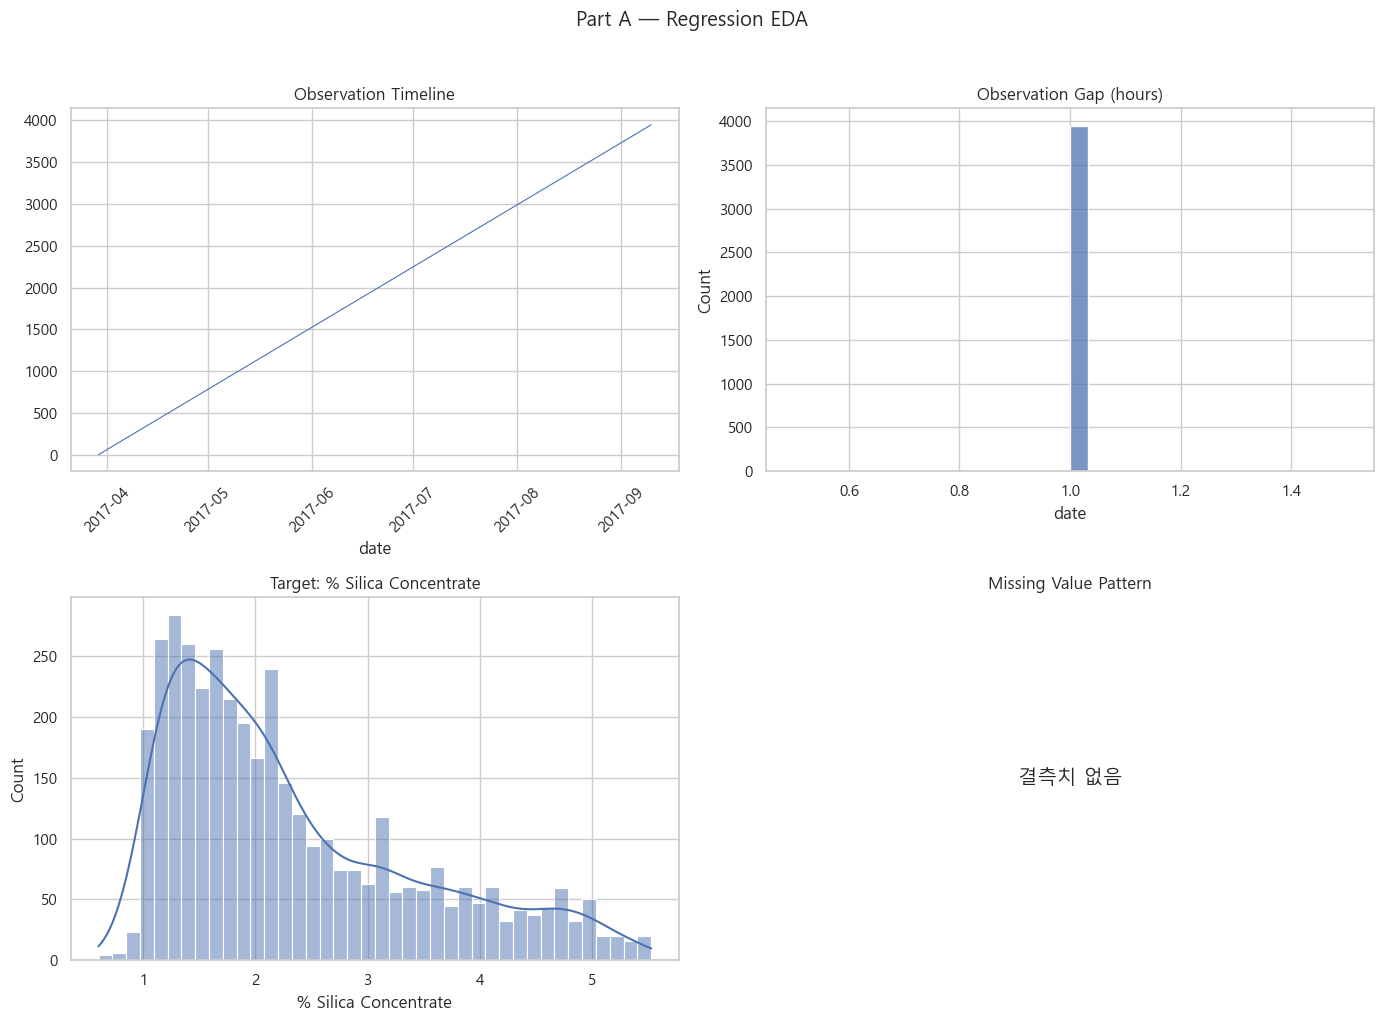

In [4]:
# ============================================================
# A-1) 회귀 데이터 EDA (전처리 전) — Regression
# ============================================================

TARGET_REG = "% Silica Concentrate"

print("=" * 60)
print("1. 기본 구조")
print("=" * 60)
print(f"행 × 열: {Regression.shape}")
print("\n[컬럼 목록]")
print(Regression.columns.tolist())
print("\n[데이터 타입]")
print(Regression.dtypes)
display(Regression.head())
display(Regression.tail())

# ============================================================
print("\n" + "=" * 60)
print("2. 결측치")
print("=" * 60)

missing = Regression.isnull().sum()
missing_pct = (missing / len(Regression) * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct(%)": missing_pct})
missing_df = missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=False)

if len(missing_df) == 0:
    print("결측치 없음")
else:
    display(missing_df)
print(f"전체 결측치 개수: {Regression.isnull().sum().sum()}")

# ============================================================
print("\n" + "=" * 60)
print("3. 수집 기간 및 시간 간격")
print("=" * 60)

print("시작 시점:", Regression["date"].min())
print("종료 시점:", Regression["date"].max())
print("수집 기간  :", Regression["date"].max() - Regression["date"].min())
print("시간순 정렬 여부:", Regression["date"].is_monotonic_increasing)

time_diff = Regression["date"].diff().dropna()
print("\n[관측 간격 요약]")
print(time_diff.describe())
print("\n[관측 간격 value_counts (상위 5)]")
print(time_diff.value_counts().head())

irregular = time_diff[time_diff != pd.Timedelta(hours=1)]
print(f"\n1시간이 아닌 간격 개수: {len(irregular)}")

# ============================================================
print("\n" + "=" * 60)
print("4. 중복 및 기본 통계")
print("=" * 60)

print("중복 행 개수:", Regression.duplicated().sum())
print("date 중복 개수:", Regression["date"].duplicated().sum())
display(Regression.describe().T)
print(f"\n[타겟: {TARGET_REG}]")
print(Regression[TARGET_REG].describe())

# 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(Regression["date"], np.arange(len(Regression)), linewidth=0.8)
axes[0, 0].set_title("Observation Timeline")
axes[0, 0].set_xlabel("date")
axes[0, 0].tick_params(axis="x", rotation=45)

gap_hours = time_diff.dt.total_seconds() / 3600
sns.histplot(gap_hours, bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Observation Gap (hours)")

sns.histplot(Regression[TARGET_REG], bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set_title(f"Target: {TARGET_REG}")

if Regression.isnull().sum().sum() > 0:
    sns.heatmap(Regression.isnull(), cbar=False, yticklabels=False, ax=axes[1, 1])
else:
    axes[1, 1].text(0.5, 0.5, "결측치 없음", ha="center", va="center", fontsize=14)
    axes[1, 1].axis("off")
axes[1, 1].set_title("Missing Value Pattern")

plt.suptitle("Part A — Regression EDA", y=1.02)
plt.tight_layout()
plt.show()

1. 기본 구조
행 × 열: (1941, 34)

[컬럼 목록]
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

[데이터 타입]
X_Minimum                  int64
X_Maximum                  int64
Y_Minimum                  int64
Y_Maximum                  int64
Pixels_Areas               int64
X_Perimeter                int64
Y_Perimeter                int64
Sum_of_Luminosity          int64
Minimum_of_Luminosity      int64
Maximum_of_Luminosity      int64
Length_of_Conveyer         int64
TypeOfSteel_A300         

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
1936,249,277,325780,325796,273,54,22,35033,119,141,...,-0.4286,0.0026,0.7254,0,0,0,0,0,0,1
1937,144,175,340581,340598,287,44,24,34599,112,133,...,-0.4516,-0.0582,0.8173,0,0,0,0,0,0,1
1938,145,174,386779,386794,292,40,22,37572,120,140,...,-0.4828,0.0052,0.7079,0,0,0,0,0,0,1
1939,137,170,422497,422528,419,97,47,52715,117,140,...,-0.0606,-0.0171,0.9919,0,0,0,0,0,0,1
1940,1261,1281,87951,87967,103,26,22,11682,101,133,...,-0.2000,-0.1139,0.5296,0,0,0,0,0,0,1



2. 결측치
결측치 없음
전체 결측치 개수: 0

3. 관측 정보 (시간 변수 없음)
※ date 컬럼 없음 → 수집 기간·간격은 확인 불가

[행별 결함 유형 합계] (One-Hot 여부)
1    1941
Name: count, dtype: int64

[타겟 K_Scatch 분포]
K_Scatch
0    1550
1     391
Name: count, dtype: int64
K_Scatch
0    0.799
1    0.201
Name: proportion, dtype: float64

이진(0/1) 변수: 9개 | 연속형: 25개

4. 중복 및 기본 통계
중복 행 개수: 0


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,5.711360e+02,5.206907e+02,0.0000,51.0000,4.350000e+02,1.053000e+03,1.705000e+03
X_Maximum,1941.0,6.179645e+02,4.976274e+02,4.0000,192.0000,4.670000e+02,1.072000e+03,1.713000e+03
Y_Minimum,1941.0,1.650685e+06,1.774578e+06,6712.0000,471253.0000,1.204128e+06,2.183073e+06,1.298766e+07
Y_Maximum,1941.0,1.650739e+06,1.774590e+06,6724.0000,471281.0000,1.204136e+06,2.183084e+06,1.298769e+07
Pixels_Areas,1941.0,1.893878e+03,5.168460e+03,2.0000,84.0000,1.740000e+02,8.220000e+02,1.526550e+05
X_Perimeter,1941.0,1.118552e+02,3.012092e+02,2.0000,15.0000,2.600000e+01,8.400000e+01,1.044900e+04
Y_Perimeter,1941.0,8.296600e+01,4.264829e+02,1.0000,13.0000,2.500000e+01,8.300000e+01,1.815200e+04
Sum_of_Luminosity,1941.0,2.063121e+05,5.122936e+05,250.0000,9522.0000,1.920200e+04,8.301100e+04,1.159141e+07
Minimum_of_Luminosity,1941.0,8.454869e+01,3.213428e+01,0.0000,63.0000,9.000000e+01,1.060000e+02,2.030000e+02
Maximum_of_Luminosity,1941.0,1.301937e+02,1.869099e+01,37.0000,124.0000,1.270000e+02,1.400000e+02,2.530000e+02


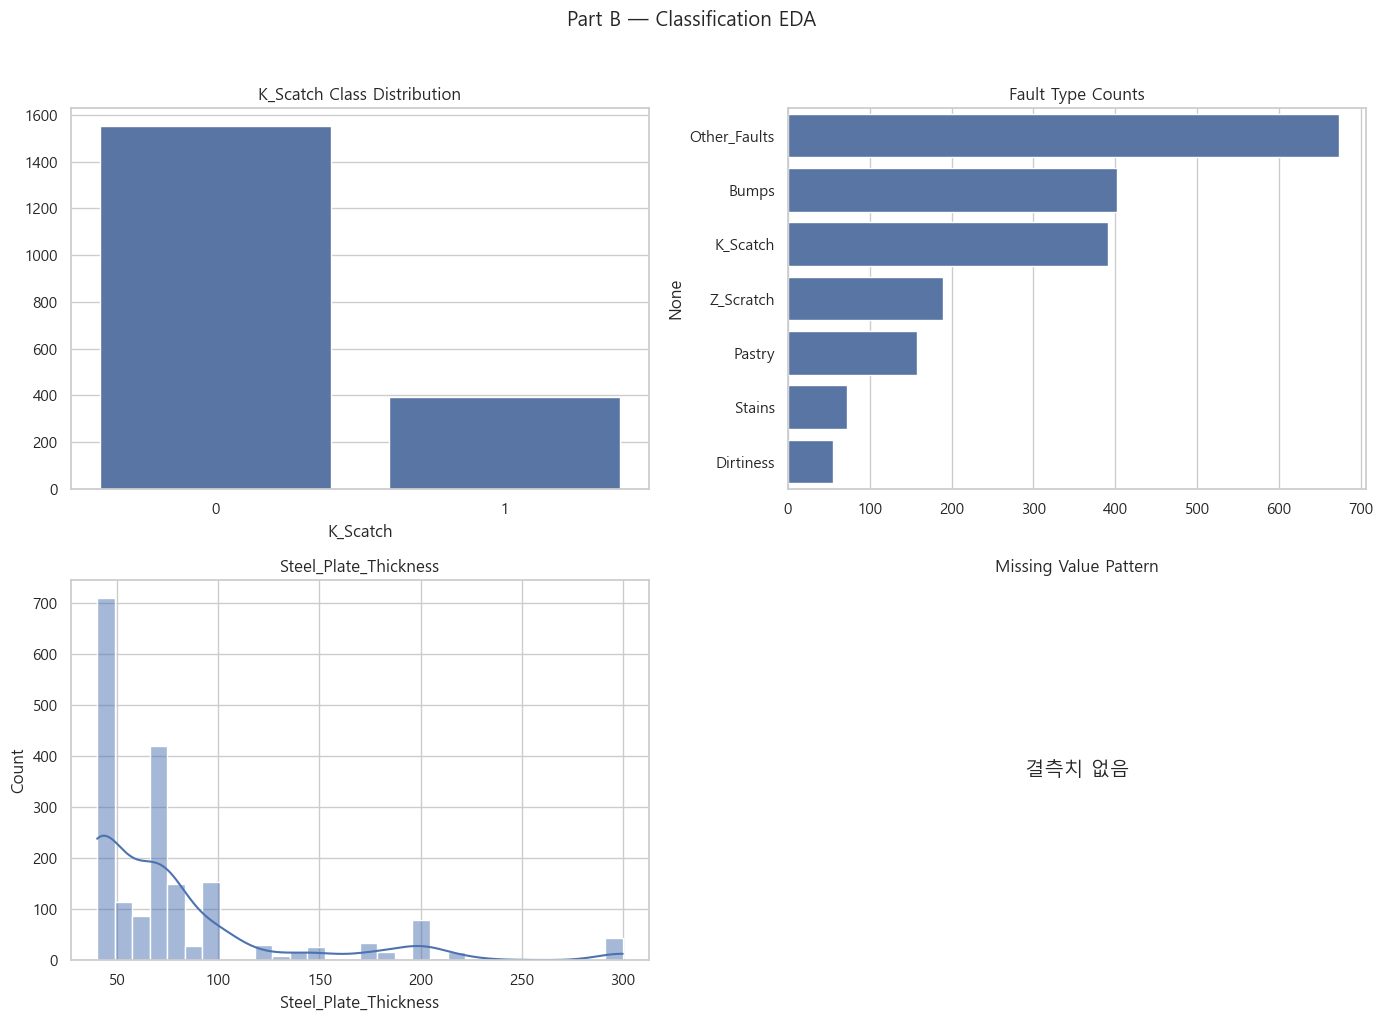

In [5]:
# ============================================================
# B-1) 분류 데이터 EDA (전처리 전) — Classification
# ============================================================

TARGET_CLS = "K_Scatch"
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]

print("=" * 60)
print("1. 기본 구조")
print("=" * 60)
print(f"행 × 열: {Classification.shape}")
print("\n[컬럼 목록]")
print(Classification.columns.tolist())
print("\n[데이터 타입]")
print(Classification.dtypes)
display(Classification.head())
display(Classification.tail())

# ============================================================
print("\n" + "=" * 60)
print("2. 결측치")
print("=" * 60)

missing_cls = Classification.isnull().sum()
missing_pct_cls = (missing_cls / len(Classification) * 100).round(2)
missing_cls_df = pd.DataFrame({"missing_count": missing_cls, "missing_pct(%)": missing_pct_cls})
missing_cls_df = missing_cls_df[missing_cls_df["missing_count"] > 0].sort_values("missing_count", ascending=False)

if len(missing_cls_df) == 0:
    print("결측치 없음")
else:
    display(missing_cls_df)
print(f"전체 결측치 개수: {Classification.isnull().sum().sum()}")

# ============================================================
print("\n" + "=" * 60)
print("3. 관측 정보 (시간 변수 없음)")
print("=" * 60)

print("※ date 컬럼 없음 → 수집 기간·간격은 확인 불가")
print("\n[행별 결함 유형 합계] (One-Hot 여부)")
print(Classification[FAULT_COLS].sum(axis=1).value_counts().sort_index())
print(f"\n[타겟 {TARGET_CLS} 분포]")
print(Classification[TARGET_CLS].value_counts())
print(Classification[TARGET_CLS].value_counts(normalize=True).round(3))

binary_cols = [c for c in Classification.columns
               if Classification[c].nunique() == 2 and set(Classification[c].unique()) <= {0, 1}]
continuous_cols = [c for c in Classification.select_dtypes(include=[np.number]).columns
                   if c not in binary_cols]
print(f"\n이진(0/1) 변수: {len(binary_cols)}개 | 연속형: {len(continuous_cols)}개")

# ============================================================
print("\n" + "=" * 60)
print("4. 중복 및 기본 통계")
print("=" * 60)

print("중복 행 개수:", Classification.duplicated().sum())
display(Classification[continuous_cols].describe().T)

# 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

counts = Classification[TARGET_CLS].value_counts().sort_index()
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=axes[0, 0])
axes[0, 0].set_title("K_Scatch Class Distribution")

fault_sum = Classification[FAULT_COLS].sum().sort_values(ascending=False)
sns.barplot(x=fault_sum.values, y=fault_sum.index, ax=axes[0, 1])
axes[0, 1].set_title("Fault Type Counts")

sns.histplot(Classification["Steel_Plate_Thickness"], bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Steel_Plate_Thickness")

if Classification.isnull().sum().sum() > 0:
    sns.heatmap(Classification.isnull(), cbar=False, yticklabels=False, ax=axes[1, 1])
else:
    axes[1, 1].text(0.5, 0.5, "결측치 없음", ha="center", va="center", fontsize=14)
    axes[1, 1].axis("off")
axes[1, 1].set_title("Missing Value Pattern")

plt.suptitle("Part B — Classification EDA", y=1.02)
plt.tight_layout()
plt.show()

### A-1-2) Graph 기반 탐색

**[과제]** 써니는 오늘도 어제처럼 시계열 변화 패턴과 변수 간 상관관계를 앙상블 모델링 전에 다시 시각화로 점검하려고 합니다. AI와 함께 시간 흐름에 따른 변수 변화를 시각화해 보세요.

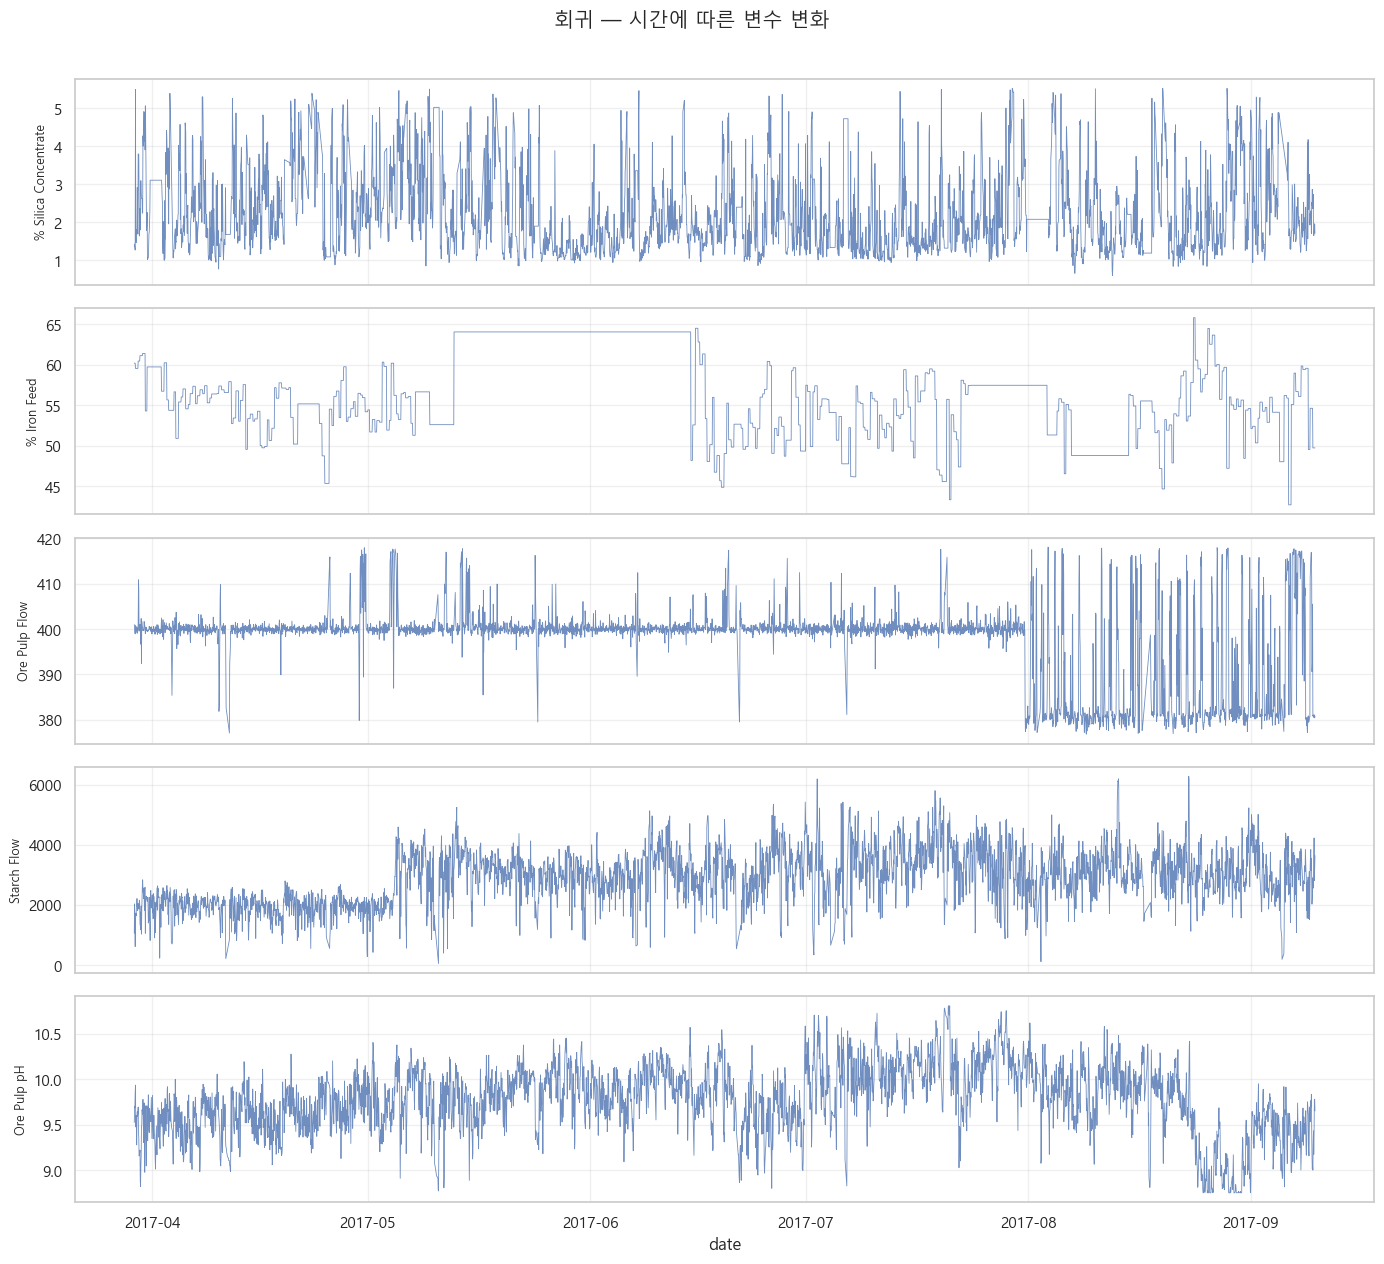

In [6]:
# 시간 인덱스 설정
df_ts = Regression.set_index("date").sort_index()

# 함께 볼 변수 (필요 시 수정)
ts_vars = [
    "% Silica Concentrate",   # 타겟
    "% Iron Feed",
    "Ore Pulp Flow",
    "Starch Flow",
    "Ore Pulp pH",
]

fig, axes = plt.subplots(len(ts_vars), 1, figsize=(14, 2.5 * len(ts_vars)), sharex=True)
for ax, col in zip(axes, ts_vars):
    ax.plot(df_ts.index, df_ts[col], linewidth=0.6, alpha=0.8)
    ax.set_ylabel(col, fontsize=9)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("date")
plt.suptitle("회귀 — 시간에 따른 변수 변화", y=1.01)
plt.tight_layout()
plt.show()

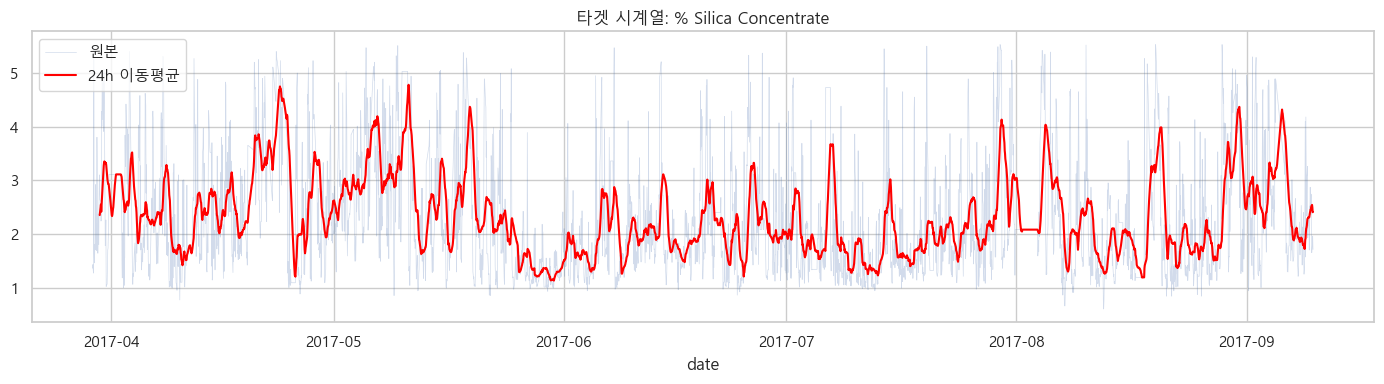

In [7]:
TARGET_REG = "% Silica Concentrate"
window = 24   # 24시간(1일) 이동평균

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_ts.index, df_ts[TARGET_REG], alpha=0.25, label="원본", linewidth=0.5)
ax.plot(df_ts.index, df_ts[TARGET_REG].rolling(window).mean(),
        color="red", linewidth=1.5, label=f"{window}h 이동평균")
ax.set_title(f"타겟 시계열: {TARGET_REG}")
ax.set_xlabel("date")
ax.legend()
plt.tight_layout()
plt.show()

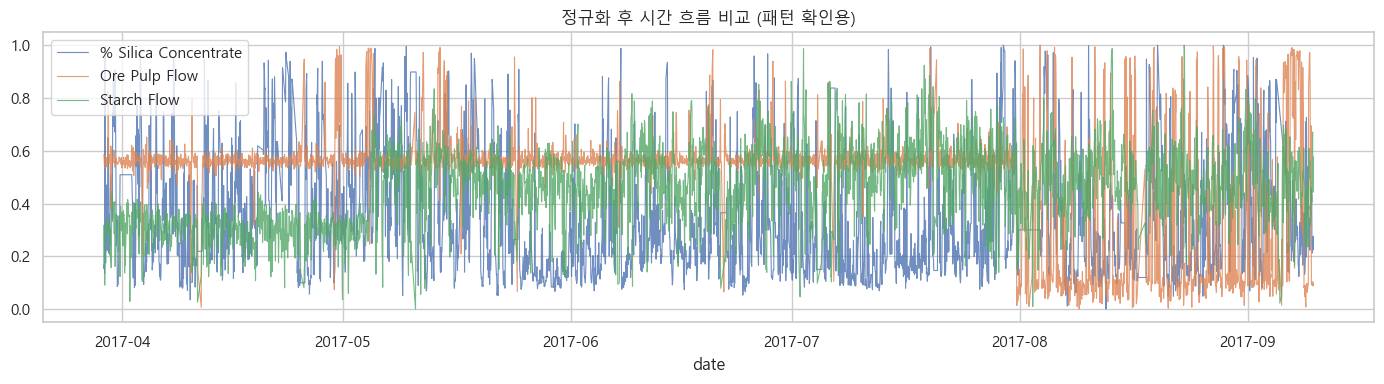

In [8]:
from sklearn.preprocessing import MinMaxScaler

compare_cols = ["% Silica Concentrate", "Ore Pulp Flow", "Starch Flow"]
scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(df_ts[compare_cols]),
    index=df_ts.index,
    columns=compare_cols,
)

plt.figure(figsize=(14, 4))
for col in compare_cols:
    plt.plot(scaled.index, scaled[col], label=col, alpha=0.8, linewidth=0.8)
plt.title("정규화 후 시간 흐름 비교 (패턴 확인용)")
plt.xlabel("date")
plt.legend()
plt.tight_layout()
plt.show()

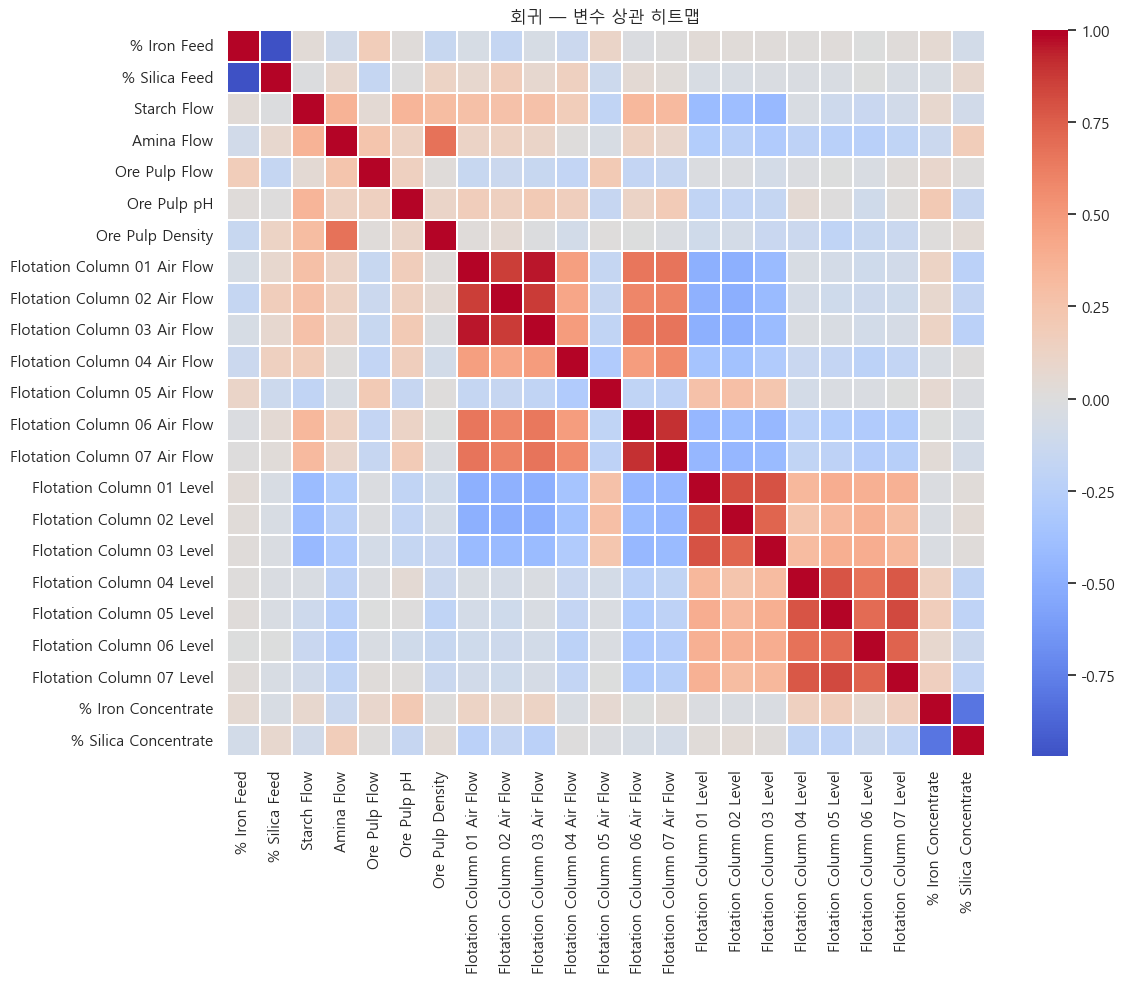

In [9]:
num_cols = Regression.drop(columns=["date"]).select_dtypes(include=[np.number])
plt.figure(figsize=(12, 10))
sns.heatmap(num_cols.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("회귀 — 변수 상관 히트맵")
plt.tight_layout()
plt.show()

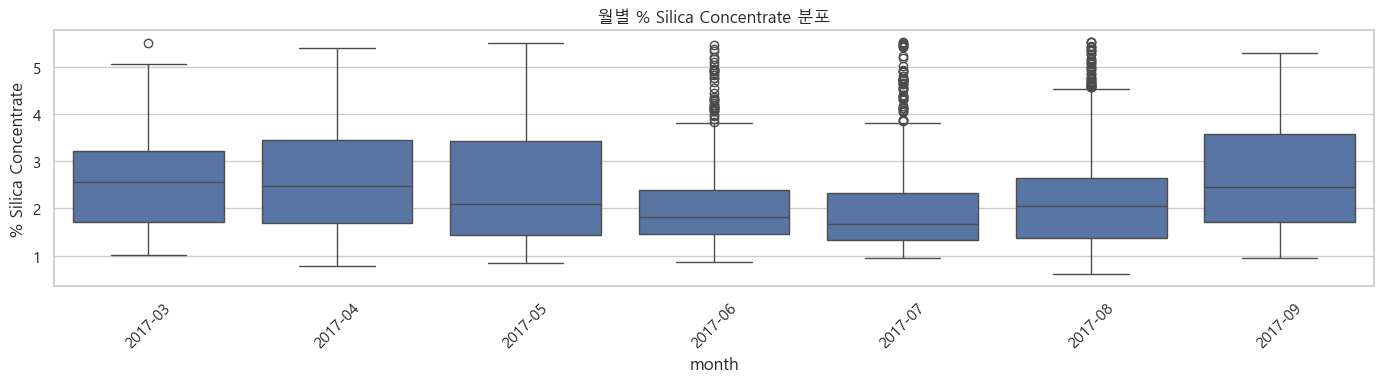

In [11]:
tmp = Regression.copy()
tmp["month"] = tmp["date"].dt.to_period("M").astype(str)

plt.figure(figsize=(14, 4))
sns.boxplot(data=tmp, x="month", y="% Silica Concentrate")
plt.xticks(rotation=45)
plt.title("월별 % Silica Concentrate 분포")
plt.tight_layout()
plt.show()

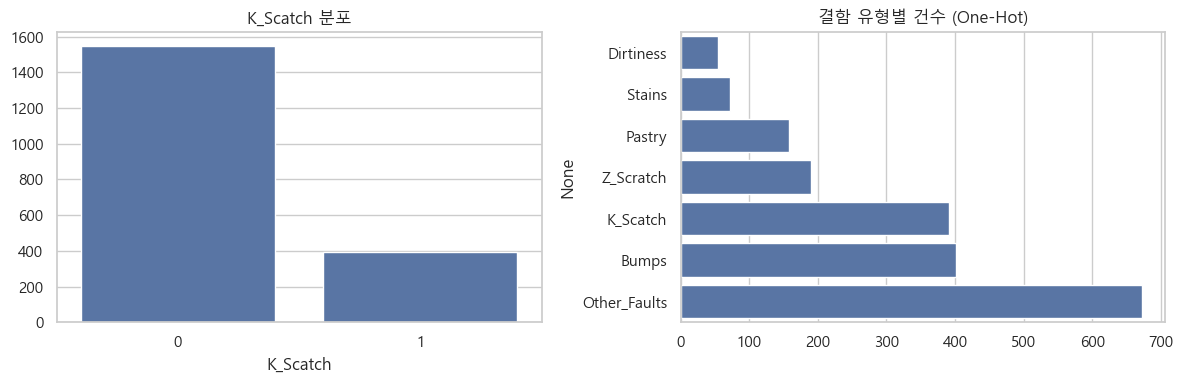

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = Classification["K_Scatch"].value_counts().sort_index()
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=axes[0])
axes[0].set_title("K_Scatch 분포")

fault_cols = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
fault_sum = Classification[fault_cols].sum().sort_values()
sns.barplot(x=fault_sum.values, y=fault_sum.index, ax=axes[1])
axes[1].set_title("결함 유형별 건수 (One-Hot)")

plt.tight_layout()
plt.show()

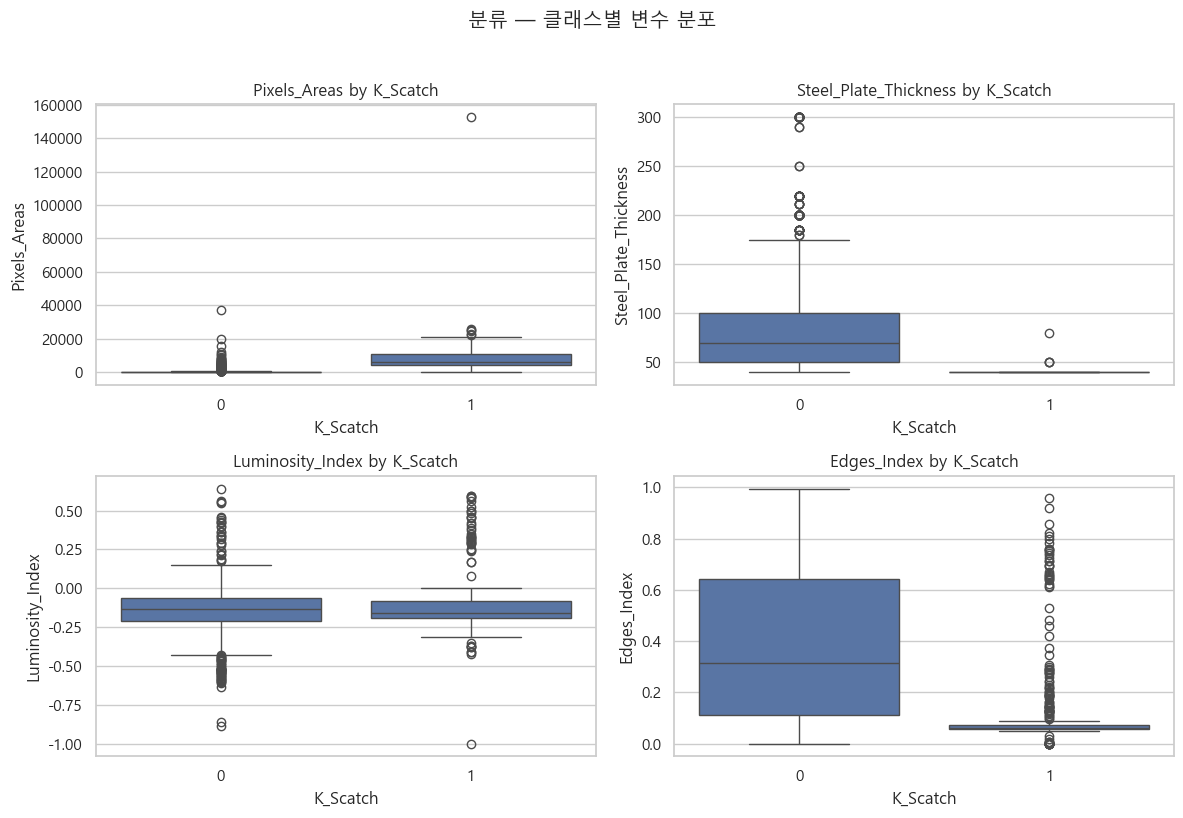

In [13]:
plot_vars = ["Pixels_Areas", "Steel_Plate_Thickness", "Luminosity_Index", "Edges_Index"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), plot_vars):
    sns.boxplot(data=Classification, x="K_Scatch", y=col, ax=ax)
    ax.set_title(f"{col} by K_Scatch")
plt.suptitle("분류 — 클래스별 변수 분포", y=1.02)
plt.tight_layout()
plt.show()

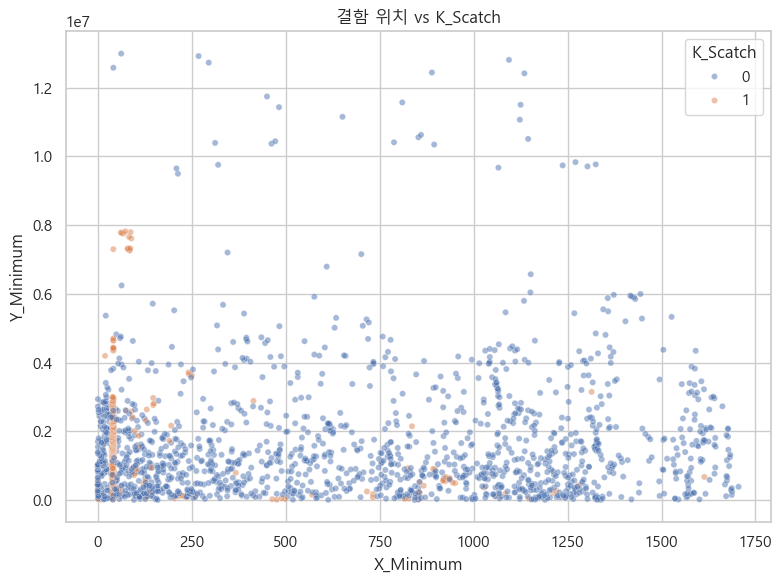

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=Classification,
    x="X_Minimum", y="Y_Minimum",
    hue="K_Scatch", alpha=0.5, s=20
)
plt.title("결함 위치 vs K_Scatch")
plt.tight_layout()
plt.show()

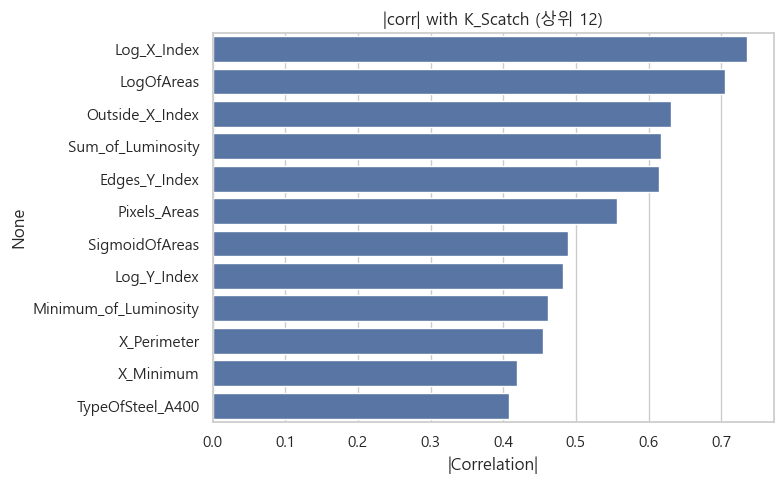

In [15]:
feature_cols = Classification.drop(columns=fault_cols).columns
corr_target = Classification[feature_cols.tolist() + ["K_Scatch"]] \
    .corr(numeric_only=True)["K_Scatch"].drop("K_Scatch").abs().sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 5))
sns.barplot(x=corr_target.values, y=corr_target.index)
plt.title("|corr| with K_Scatch (상위 12)")
plt.xlabel("|Correlation|")
plt.tight_layout()
plt.show()

**[과제]** 써니는 변수들 간에 강하게 얽혀 있는 관계(다중공선성 후보)가 있는지 한눈에 살펴보고 싶습니다. AI와 상의해서 상관관계 히트맵을 그려보고 트리 기반 앙상블 모델에서는 이 다중공선성이 Day 2의 선형 모델만큼 문제가 되는지도 함께 생각해 보세요.

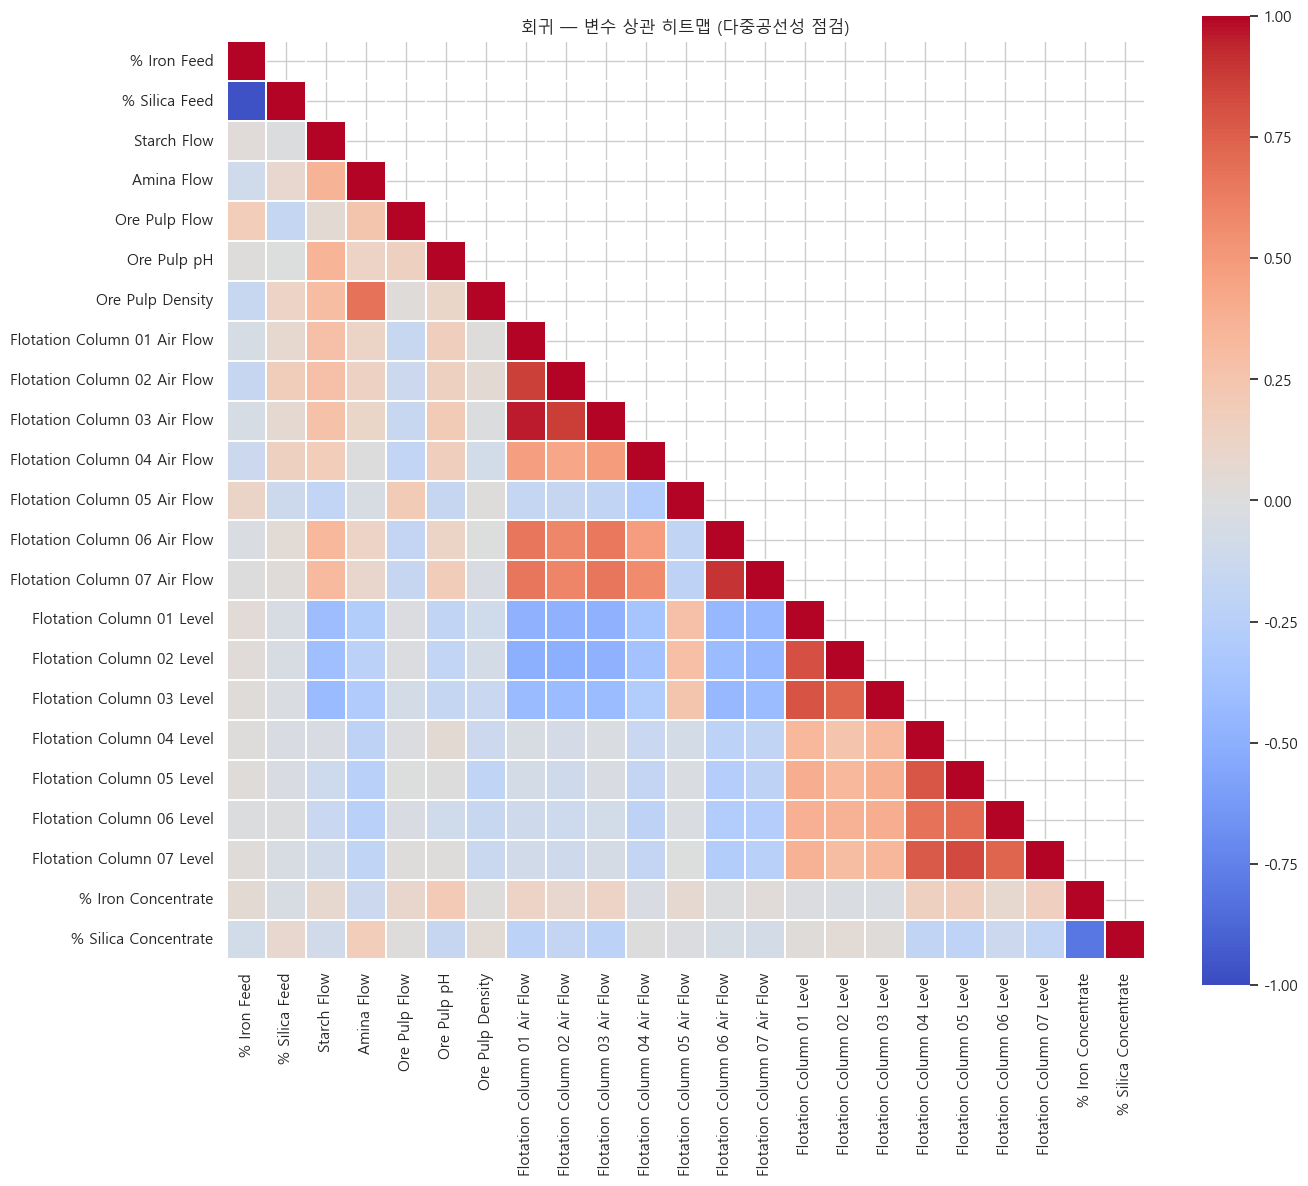

=== 회귀 |상관| >= 0.8 인 변수 쌍 ===


,var1,var2,corr
0,% Iron Feed,% Silica Feed,-0.9720
2,Flotation Column 01 Air Flow,Flotation Column 03 Air Flow,0.9583
4,Flotation Column 06 Air Flow,Flotation Column 07 Air Flow,0.9030
3,Flotation Column 02 Air Flow,Flotation Column 03 Air Flow,0.8749
1,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,0.8619
6,Flotation Column 05 Level,Flotation Column 07 Level,0.8298
5,Flotation Column 01 Level,Flotation Column 02 Level,0.8072
7,% Iron Concentrate,% Silica Concentrate,-0.8027


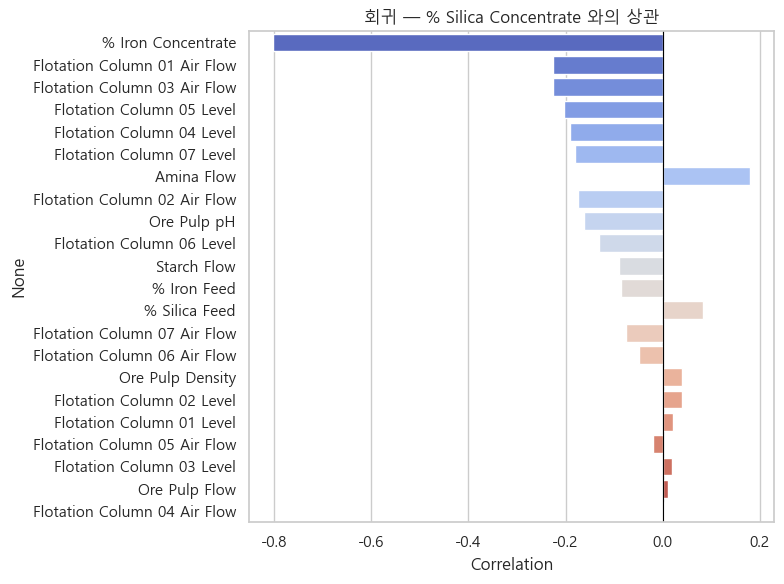

In [16]:
# ============================================================
# 회귀 — 상관 히트맵 (다중공선성 점검)
# ============================================================

TARGET_REG = "% Silica Concentrate"

# date 제외, 수치형만
reg_num = Regression.drop(columns=["date"]).select_dtypes(include=[np.number])
reg_corr = reg_num.corr()

# (1) 전체 히트맵
plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(reg_corr, dtype=bool), k=1)  # 상삼각 마스크(중복 제거)
sns.heatmap(
    reg_corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.3,
    square=True,
)
plt.title("회귀 — 변수 상관 히트맵 (다중공선성 점검)")
plt.tight_layout()
plt.show()

# (2) |상관| 높은 쌍 출력 (자기 자신 제외)
threshold = 0.8
high_corr_reg = []

for i in range(len(reg_corr.columns)):
    for j in range(i + 1, len(reg_corr.columns)):
        val = reg_corr.iloc[i, j]
        if abs(val) >= threshold:
            high_corr_reg.append({
                "var1": reg_corr.columns[i],
                "var2": reg_corr.columns[j],
                "corr": round(val, 4)
            })

high_corr_reg_df = pd.DataFrame(high_corr_reg).sort_values("corr", key=abs, ascending=False)
print(f"=== 회귀 |상관| >= {threshold} 인 변수 쌍 ===")
if len(high_corr_reg_df) == 0:
    print("해당 없음")
else:
    display(high_corr_reg_df)

# (3) 타겟과의 상관 (참고)
target_corr_reg = reg_corr[TARGET_REG].drop(TARGET_REG).sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(x=target_corr_reg.values, y=target_corr_reg.index, palette="coolwarm")
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"회귀 — {TARGET_REG} 와의 상관")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

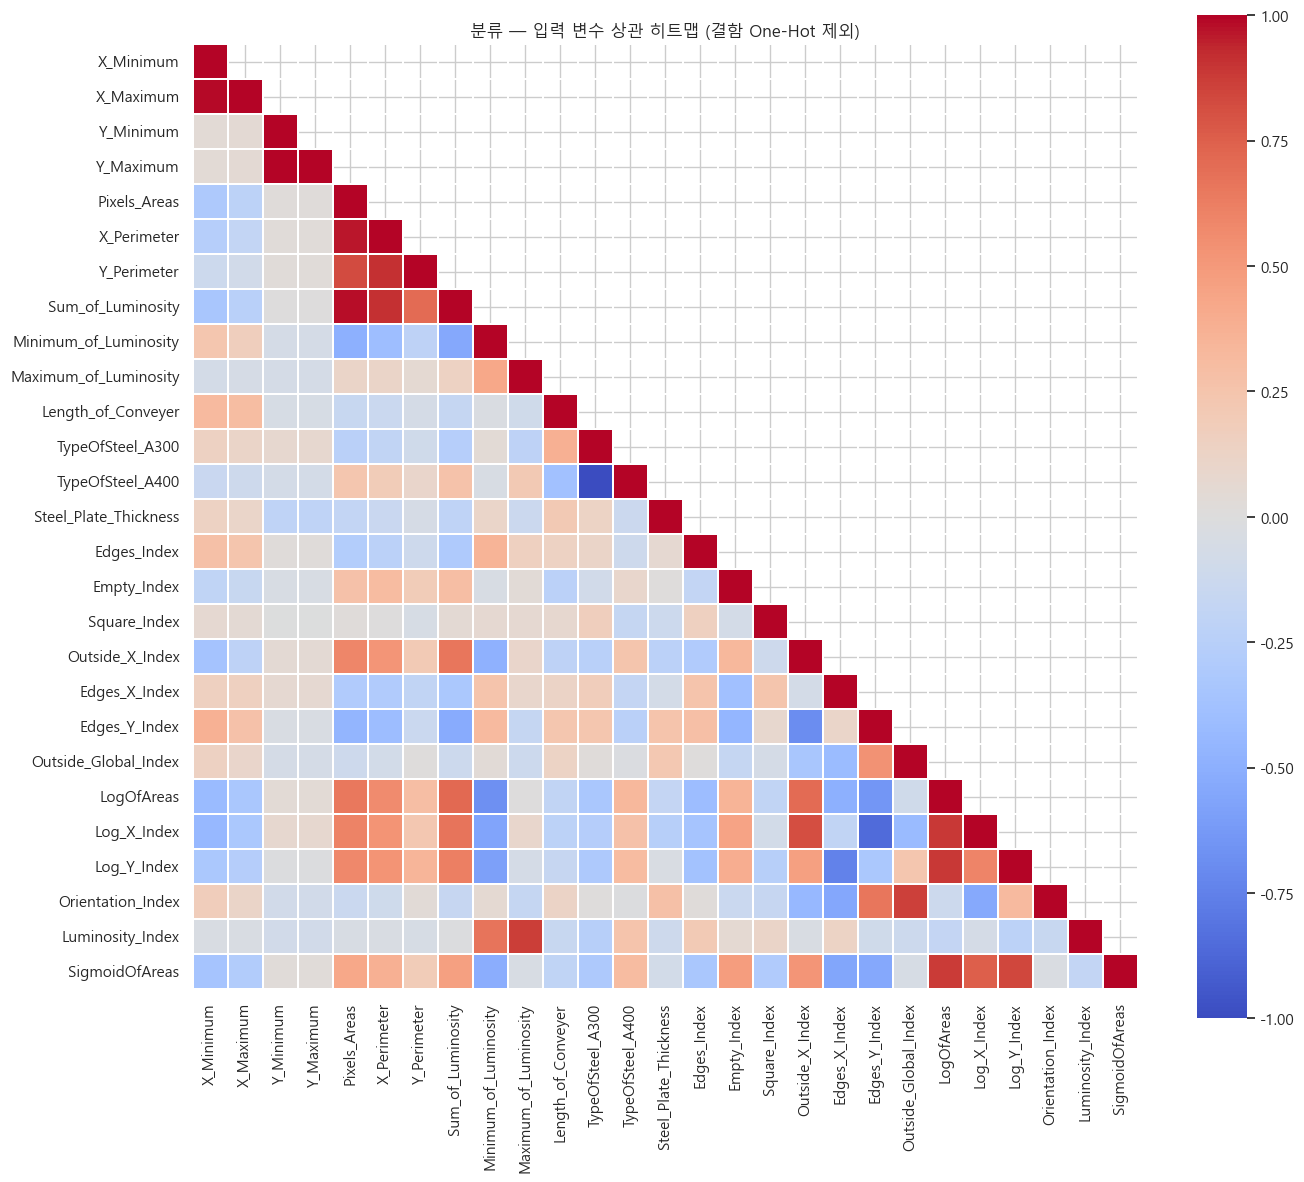

=== 분류 |상관| >= 0.8 인 변수 쌍 ===


,var1,var2,corr
1,Y_Minimum,Y_Maximum,1.0000
8,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000
0,X_Minimum,X_Maximum,0.9883
4,Pixels_Areas,Sum_of_Luminosity,0.9790
2,Pixels_Areas,X_Perimeter,0.9666
6,X_Perimeter,Sum_of_Luminosity,0.9130
5,X_Perimeter,Y_Perimeter,0.9124
12,LogOfAreas,Log_X_Index,0.8889
13,LogOfAreas,Log_Y_Index,0.8830
14,LogOfAreas,SigmoidOfAreas,0.8778


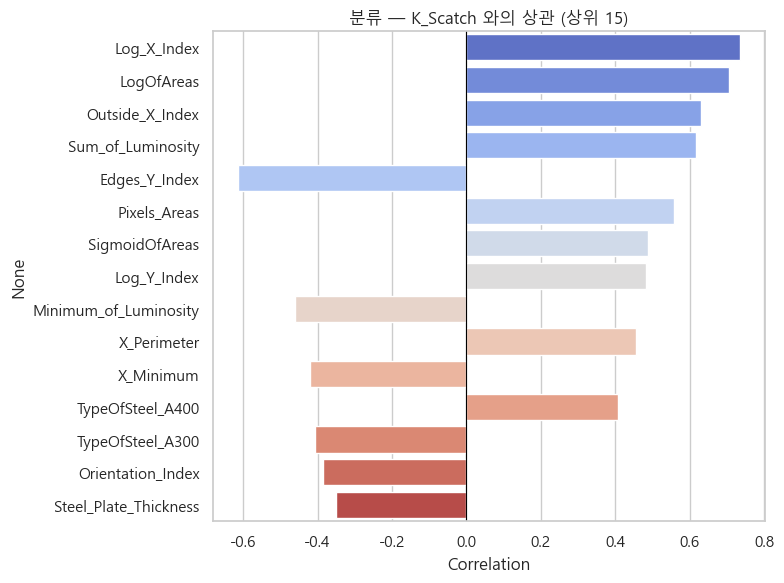

In [17]:
# ============================================================
# 분류 — 상관 히트맵 (다중공선성 점검)
# ============================================================

TARGET_CLS = "K_Scatch"
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]

# 모델 입력 후보: 결함 유형 컬럼 제외
cls_features = Classification.drop(columns=FAULT_COLS).select_dtypes(include=[np.number])
cls_corr = cls_features.corr()

# (1) 전체 히트맵
plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(cls_corr, dtype=bool), k=1)
sns.heatmap(
    cls_corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.3,
    square=True,
)
plt.title("분류 — 입력 변수 상관 히트맵 (결함 One-Hot 제외)")
plt.tight_layout()
plt.show()

# (2) |상관| 높은 쌍
threshold = 0.8
high_corr_cls = []

for i in range(len(cls_corr.columns)):
    for j in range(i + 1, len(cls_corr.columns)):
        val = cls_corr.iloc[i, j]
        if abs(val) >= threshold:
            high_corr_cls.append({
                "var1": cls_corr.columns[i],
                "var2": cls_corr.columns[j],
                "corr": round(val, 4)
            })

high_corr_cls_df = pd.DataFrame(high_corr_cls).sort_values("corr", key=abs, ascending=False)
print(f"=== 분류 |상관| >= {threshold} 인 변수 쌍 ===")
if len(high_corr_cls_df) == 0:
    print("해당 없음")
else:
    display(high_corr_cls_df)

# (3) K_Scatch와의 상관 (타겟은 fault_cols에서 따로 정의)
target_corr_cls = Classification.drop(columns=[c for c in FAULT_COLS if c != TARGET_CLS]) \
    .corr(numeric_only=True)[TARGET_CLS].drop(TARGET_CLS, errors="ignore") \
    .sort_values(key=abs, ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=target_corr_cls.values, y=target_corr_cls.index, palette="coolwarm")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("분류 — K_Scatch 와의 상관 (상위 15)")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

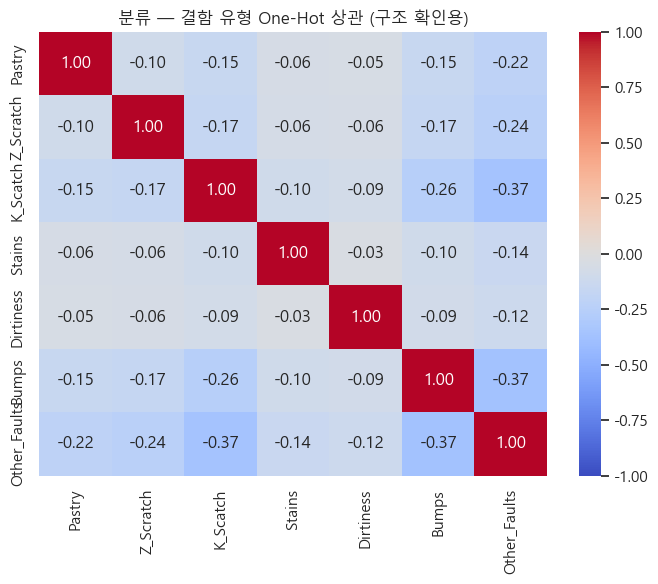

In [18]:
# 결함 유형 컬럼만 — 구조 확인용 (해석 주의)
fault_corr = Classification[FAULT_COLS].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(fault_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("분류 — 결함 유형 One-Hot 상관 (구조 확인용)")
plt.tight_layout()
plt.show()

---
## A-2) 데이터 전처리

### A-2-1) 불필요한 변수 제거 및 결측치 확인

**[과제]** 써니는 Heatmap을 통해 타겟변수와 강한 상관관계를 가지는 변수를 발견하였습니다. 해당 변수가 데이터 누수를 유발할 수 있는지가 궁금해졌습니다. AI와 함께 상의하여 해당 변수 제거 여부를 검토하고 결정해보세요.

In [ ]:
# ============================================================
# 회귀 — 데이터 누수 변수 제거 후 X / y 분리
# ============================================================

TARGET_REG = "% Silica Concentrate"

# 1) 누수 변수 제거
Regression = Regression.drop(columns=["% Iron Concentrate"])

# 2) y / X 분리
Y_reg = Regression[TARGET_REG]
X_reg = Regression.drop(columns=["date", TARGET_REG])

# 3) 확인
print("=== 회귀 X / y 분리 결과 ===")
print("Y_reg:", Y_reg.shape, "| dtype:", Y_reg.dtype)
print("X_reg:", X_reg.shape)
print("\n[타겟 기술통계]")
print(Y_reg.describe())
print("\n[X_reg 컬럼]")
print(X_reg.columns.tolist())

=== 회귀 X / y 분리 결과 ===
Y_reg: (3948,) | dtype: float64
X_reg: (3948, 21)

[타겟 기술통계]
count    3948.000000
mean        2.322261
std         1.120117
min         0.600000
25%         1.440000
50%         2.000000
75%         2.992500
max         5.530000
Name: % Silica Concentrate, dtype: float64

[X_reg 컬럼]
['% Iron Feed', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level']


In [20]:
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]

Y_cls = Classification["K_Scatch"]
X_cls = Classification.drop(columns=FAULT_COLS)   # 결함 7개 전부 제거

### A-2-2) 입출력 변수 분할 및 데이터 분할

**[과제]** 써니는 `% Silica Concentrate`를 예측하기 위해 입력변수와 타겟 변수를 분리하려고 합니다. Day 2와 마찬가지로 시계열 데이터라는 점을 고려하여 데이터를 분할해보세요.

In [27]:
# 시간순 Hold-out: 앞 70% Train, 뒤 30% Test
TEST_SIZE = 0.3

split_idx = int(len(X_reg) * (1 - TEST_SIZE))

X_reg_train = X_reg.iloc[:split_idx].copy()
X_reg_test  = X_reg.iloc[split_idx:].copy()
Y_reg_train = Y_reg.iloc[:split_idx].copy()
Y_reg_test  = Y_reg.iloc[split_idx:].copy()

dates = Regression["date"]

date_train = dates.iloc[:split_idx]
date_test  = dates.iloc[split_idx:]

print("=== 회귀 Train / Test (시간순) ===")
print("전체:", X_reg.shape)
print("Train:", X_reg_train.shape, "|", date_train.iloc[0], "~", date_train.iloc[-1])
print("Test :", X_reg_test.shape,  "|", date_test.iloc[0],  "~", date_test.iloc[-1])
print("시간순 유지:", date_train.iloc[-1] < date_test.iloc[0])

=== 회귀 Train / Test (시간순) ===
전체: (3948, 21)
Train: (2763, 21) | 2017-03-29 12:00:00 ~ 2017-07-22 14:00:00
Test : (1185, 21) | 2017-07-22 15:00:00 ~ 2017-09-09 23:00:00
시간순 유지: True


### A-2-3) 스케일링 필요 여부 검토

**[과제]** 써니는 Day 2에서는 Ridge/Lasso 모델 특성 때문에 StandardScaler를 적용했었는데 Day 3에서 사용할 Random Forest·GBM·XGBoost·LightGBM·CatBoost도 스케일링이 꼭 필요한지 AI와 상의해서 판단해 보세요.

In [ ]:
#필요 없음

---
## A-3) 모델 학습 및 예측

**[과제]** 써니는 Day 2에서 학습한 회귀 모델과 Day 3에서 학습한 앙상블 모델을 동일한 데이터셋에 적용하여 성능을 비교해 보고자 합니다. AI와 함께 모델 학습, 예측, 성능 평가 코드를 작성하고, 여러 모델의 결과를 한눈에 비교할 수 있는 방법을 찾아 성능을 비교 및 분석해 보세요.

In [28]:
# ============================================================
# 모델 성능 비교 — 결과 저장 리스트
# ============================================================
reg_results = []   # 각 모델 학습 후 append
reg_models  = {}   # 학습된 모델 저장 (선택)

In [29]:
def eval_reg_model(name, model, X_tr, Y_tr, X_te, Y_te):
    """학습·예측·지표 계산 후 결과 반환"""
    model.fit(X_tr, Y_tr)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    result = {
        "Model": name,
        "Train_R2":   r2_score(Y_tr, pred_tr),
        "Test_R2":    r2_score(Y_te, pred_te),
        "Train_RMSE": np.sqrt(mean_squared_error(Y_tr, pred_tr)),
        "Test_RMSE":  np.sqrt(mean_squared_error(Y_te, pred_te)),
        "Train_MAE":  mean_absolute_error(Y_tr, pred_tr),
        "Test_MAE":   mean_absolute_error(Y_te, pred_te),
        "pred_train": pred_tr,
        "pred_test":  pred_te,
    }
    return model, result

In [30]:
# ============================================================
# Random Forest Regressor
# ============================================================
RF_reg = RandomForestRegressor(random_state=0)
RF_reg, res_rf = eval_reg_model(
    "Random Forest", RF_reg,
    X_reg_train, Y_reg_train, X_reg_test, Y_reg_test
)
reg_results.append(res_rf)
reg_models["Random Forest"] = RF_reg

print("=== Random Forest ===")
get_regscore(Y_reg_test, res_rf["pred_test"])

=== Random Forest ===
MSE       : 1.175
RMSE      : 1.084
MAE       : 0.868
R-squared : 0.087


In [31]:
# ============================================================
# GBM (Gradient Boosting)
# ============================================================
GBM_reg = GradientBoostingRegressor(random_state=0)
GBM_reg, res_gbm = eval_reg_model(
    "GBM", GBM_reg,
    X_reg_train, Y_reg_train, X_reg_test, Y_reg_test
)
reg_results.append(res_gbm)
reg_models["GBM"] = GBM_reg

print("=== GBM ===")
get_regscore(Y_reg_test, res_gbm["pred_test"])

=== GBM ===
MSE       : 1.118
RMSE      : 1.057
MAE       : 0.825
R-squared : 0.132


In [32]:
# ============================================================
# XGBoost
# ============================================================
XGB_reg = XGBRegressor(random_state=0)
XGB_reg, res_xgb = eval_reg_model(
    "XGBoost", XGB_reg,
    X_reg_train, Y_reg_train, X_reg_test, Y_reg_test
)
reg_results.append(res_xgb)
reg_models["XGBoost"] = XGB_reg

print("=== XGBoost ===")
get_regscore(Y_reg_test, res_xgb["pred_test"])

=== XGBoost ===
MSE       : 1.331
RMSE      : 1.154
MAE       : 0.905
R-squared : -0.034


In [33]:
# ============================================================
# LightGBM
# ============================================================
LGBM_reg = LGBMRegressor(random_state=0, verbose=-1)
LGBM_reg, res_lgbm = eval_reg_model(
    "LightGBM", LGBM_reg,
    X_reg_train, Y_reg_train, X_reg_test, Y_reg_test
)
reg_results.append(res_lgbm)
reg_models["LightGBM"] = LGBM_reg

print("=== LightGBM ===")
get_regscore(Y_reg_test, res_lgbm["pred_test"])

=== LightGBM ===
MSE       : 1.209
RMSE      : 1.100
MAE       : 0.836
R-squared : 0.060


In [34]:
# ============================================================
# CatBoost
# ============================================================
CAT_reg = CatBoostRegressor(random_state=0, verbose=0)
CAT_reg, res_cat = eval_reg_model(
    "CatBoost", CAT_reg,
    X_reg_train, Y_reg_train, X_reg_test, Y_reg_test
)
reg_results.append(res_cat)
reg_models["CatBoost"] = CAT_reg

print("=== CatBoost ===")
get_regscore(Y_reg_test, res_cat["pred_test"])

=== CatBoost ===
MSE       : 1.167
RMSE      : 1.080
MAE       : 0.853
R-squared : 0.093


=== 모델별 성능 요약 ===
        Model  Train_R2  Test_R2  Train_RMSE  Test_RMSE  Train_MAE  Test_MAE
Random Forest    0.9117   0.0866      0.3309     1.0842     0.2488    0.8681
          GBM    0.4763   0.1316      0.8057     1.0571     0.6189    0.8248
      XGBoost    0.9839  -0.0343      0.1412     1.1537     0.1012    0.9049
     LightGBM    0.8436   0.0602      0.4403     1.0997     0.3333    0.8363
     CatBoost    0.8685   0.0934      0.4037     1.0802     0.3038    0.8534


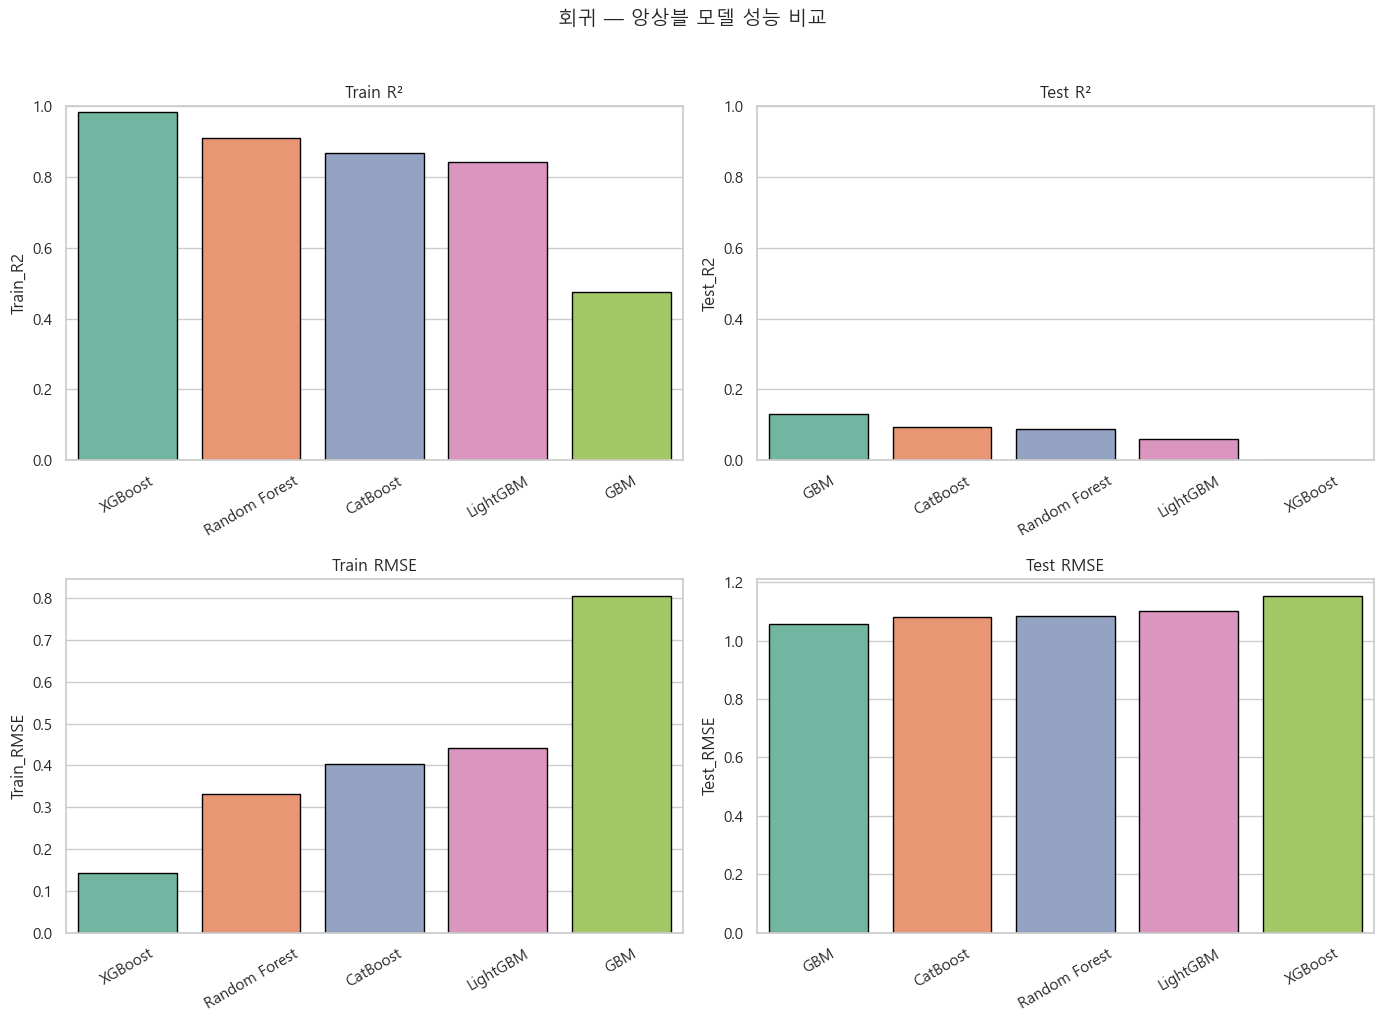

In [35]:
# ============================================================
# 5개 모델 성능 비교 시각화 (subplot)
# ============================================================
result_df = pd.DataFrame(reg_results)[
    ["Model", "Train_R2", "Test_R2", "Train_RMSE", "Test_RMSE", "Train_MAE", "Test_MAE"]
]
print("=== 모델별 성능 요약 ===")
print(result_df.round(4).to_string(index=False))

# long format (barplot용)
plot_df = result_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics_plot = [
    (0, 0, "Train_R2",   "Train R²"),
    (0, 1, "Test_R2",    "Test R²"),
    (1, 0, "Train_RMSE", "Train RMSE"),
    (1, 1, "Test_RMSE",  "Test RMSE"),
]

for row, col, metric, title in metrics_plot:
    ax = axes[row, col]
    sub = result_df.sort_values(metric, ascending=(metric.endswith("RMSE")))
    colors = sns.color_palette("Set2", len(sub))
    sns.barplot(data=sub, x="Model", y=metric, palette=colors, ax=ax, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    if metric.endswith("R2"):
        ax.set_ylim(0, 1)

plt.suptitle("회귀 — 앙상블 모델 성능 비교", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

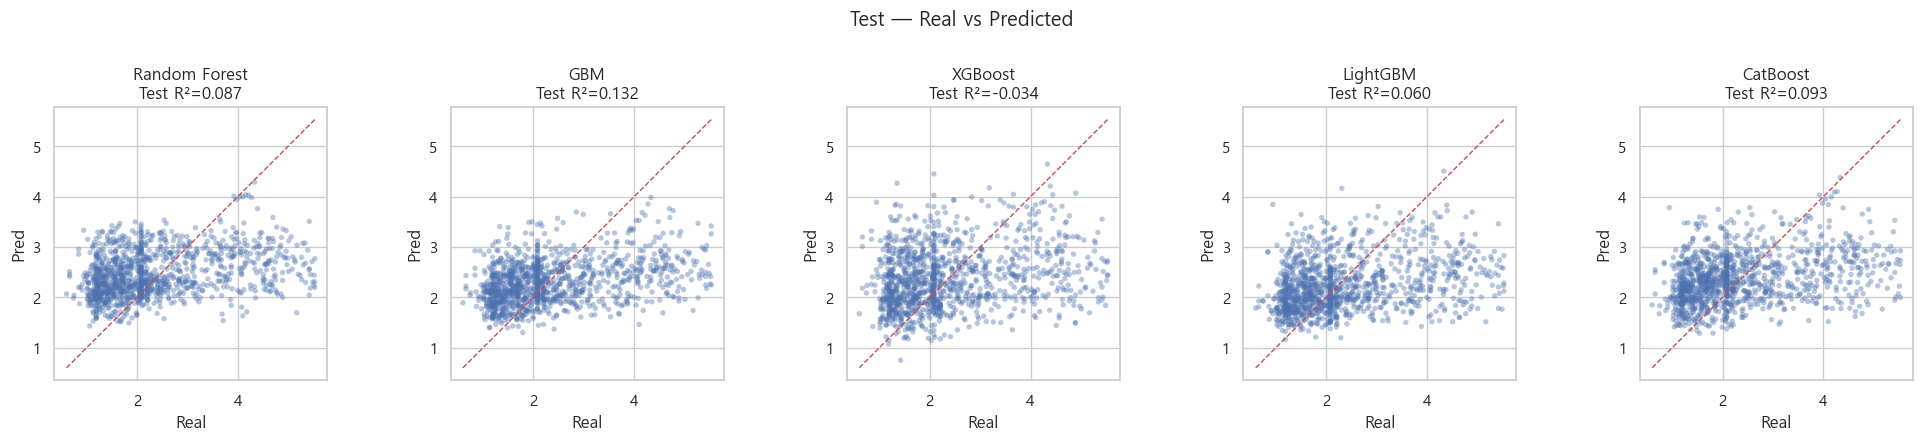

In [36]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, res in zip(axes, reg_results):
    ax.scatter(Y_reg_test, res["pred_test"], alpha=0.4, s=15, edgecolors="none")
    lims = [min(Y_reg_test.min(), res["pred_test"].min()),
            max(Y_reg_test.max(), res["pred_test"].max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_title(f"{res['Model']}\nTest R²={res['Test_R2']:.3f}")
    ax.set_xlabel("Real")
    ax.set_ylabel("Pred")
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Test — Real vs Predicted", y=1.05)
plt.tight_layout()
plt.show()

---
## A-4) 모델 결과 분석 및 고도화

**[과제]** 써니는 Day 2에서 학습한 회귀 모델들과 Day 3에서 학습한 앙상블 모델들이 중요하다고 판단하는 공정 변수가 모델에 따라 얼마나 일관되게 나타나는지 궁금해졌습니다. AI와 함께 변수 중요도 및 회귀 계수를 비교할 수 있는 코드를 작성하고 여러 모델에서 공통적으로 중요하게 선정되는 핵심 공정 변수가 무엇인지 분석해 보세요.

=== 정규화된 변수 중요도 (전체) ===


,Random Forest,GBM,XGBoost,LightGBM,CatBoost
% Iron Feed,0.0342,0.0575,0.0280,0.0557,0.0563
% Silica Feed,0.0470,0.0821,0.1217,0.0567,0.0737
Starch Flow,0.0466,0.0330,0.0288,0.0493,0.0526
Amina Flow,0.0767,0.0906,0.0507,0.0657,0.0815
Ore Pulp Flow,0.0389,0.0165,0.0243,0.0533,0.0371
Ore Pulp pH,0.0475,0.0360,0.0411,0.0627,0.0441
Ore Pulp Density,0.0439,0.0337,0.0395,0.0523,0.0485
Flotation Column 01 Air Flow,0.0686,0.0748,0.0370,0.0527,0.0561
Flotation Column 02 Air Flow,0.0354,0.0167,0.0297,0.0443,0.0353
Flotation Column 03 Air Flow,0.1021,0.1873,0.1073,0.0310,0.0687



=== 모델별 Top 10 변수 ===

[Random Forest]
  Flotation Column 03 Air Flow: 0.1021
  Amina Flow: 0.0767
  Flotation Column 04 Air Flow: 0.0714
  Flotation Column 01 Air Flow: 0.0686
  Flotation Column 03 Level: 0.0548
  Flotation Column 06 Level: 0.0503
  Ore Pulp pH: 0.0475
  % Silica Feed: 0.0470
  Starch Flow: 0.0466
  Ore Pulp Density: 0.0439

[GBM]
  Flotation Column 03 Air Flow: 0.1873
  Flotation Column 04 Air Flow: 0.0961
  Amina Flow: 0.0906
  % Silica Feed: 0.0821
  Flotation Column 01 Air Flow: 0.0748
  Flotation Column 07 Level: 0.0577
  % Iron Feed: 0.0575
  Flotation Column 05 Air Flow: 0.0370
  Ore Pulp pH: 0.0360
  Flotation Column 06 Level: 0.0356

[XGBoost]
  % Silica Feed: 0.1217
  Flotation Column 03 Air Flow: 0.1073
  Flotation Column 04 Air Flow: 0.0663
  Flotation Column 07 Level: 0.0660
  Flotation Column 06 Level: 0.0587
  Amina Flow: 0.0507
  Flotation Column 03 Level: 0.0499
  Flotation Column 02 Level: 0.0496
  Ore Pulp pH: 0.0411
  Flotation Column 05 Level: 0.

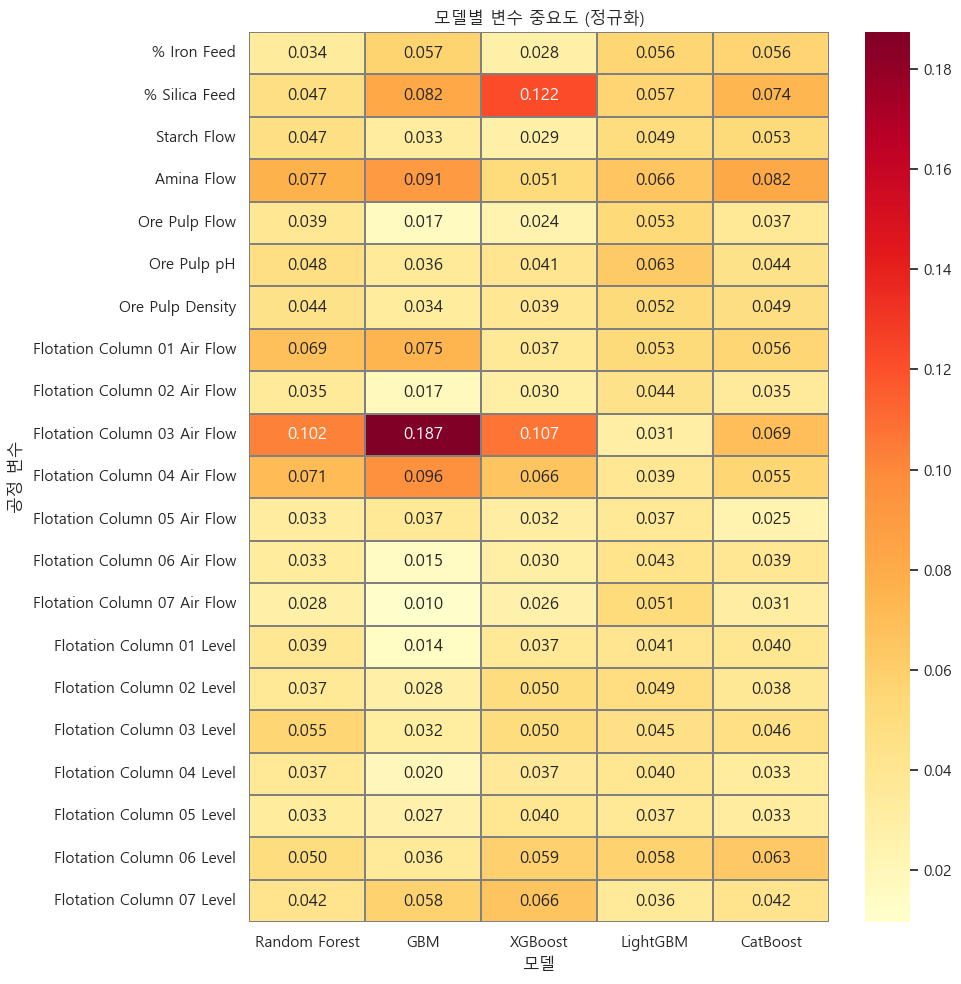

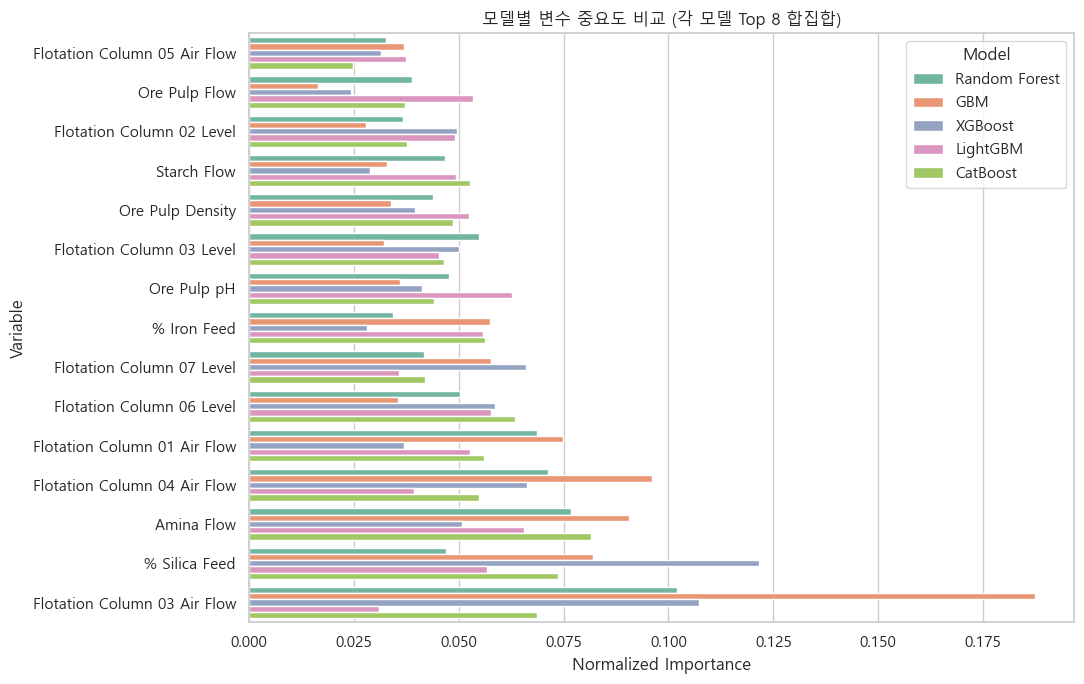

In [38]:
# ============================================================
# 1단계: 모델별 변수 중요도 추출 및 비교
# ============================================================
feature_names = X_reg_train.columns.tolist()
# (1) 모델별 raw importance
importance_raw = pd.DataFrame(index=feature_names)
for name, model in reg_models.items():
    importance_raw[name] = model.feature_importances_

# (2) 모델별 합=1 정규화 (스케일 차이 보정)
importance_norm = importance_raw.div(importance_raw.sum(axis=0), axis=1)

print("=== 정규화된 변수 중요도 (전체) ===")
display(importance_norm.round(4))

# (3) 모델별 Top 10
print("\n=== 모델별 Top 10 변수 ===")
for name in reg_models:
    top10 = importance_norm[name].sort_values(ascending=False).head(10)
    print(f"\n[{name}]")
    for var, imp in top10.items():
        print(f"  {var}: {imp:.4f}")

# (4) 히트맵 — 변수 × 모델
plt.figure(figsize=(10, 10))
sns.heatmap(
    importance_norm,
    annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.3, linecolor="gray"
)
plt.title("모델별 변수 중요도 (정규화)")
plt.ylabel("공정 변수")
plt.xlabel("모델")
plt.tight_layout()
plt.show()

# (5) 가로 막대 — y=변수, x=중요도, hue=모델 (상위 변수만)
TOP_K_PLOT = 8
top_vars_union = set()
for name in reg_models:
    top_vars_union.update(
        importance_norm[name].sort_values(ascending=False).head(TOP_K_PLOT).index
    )
top_vars_union = sorted(top_vars_union)

imp_long = importance_norm.loc[top_vars_union].reset_index().melt(
    id_vars="index", var_name="Model", value_name="Importance"
)
imp_long.rename(columns={"index": "Variable"}, inplace=True)

var_order = (
    imp_long.groupby("Variable")["Importance"]
    .mean().sort_values(ascending=True).index.tolist()
)
imp_long["Variable"] = pd.Categorical(imp_long["Variable"], categories=var_order, ordered=True)

plt.figure(figsize=(11, 7))
sns.barplot(data=imp_long, y="Variable", x="Importance", hue="Model", palette="Set2")
plt.title(f"모델별 변수 중요도 비교 (각 모델 Top {TOP_K_PLOT} 합집합)")
plt.xlabel("Normalized Importance")
plt.tight_layout()
plt.show()

**[과제]** 써니는 가장 우수했던 모델의 성능을 하이퍼파라미터 튜닝으로 더 끌어올리고 싶습니다. AI와 함께 어떤 하이퍼파라미터를 어느 범위까지 탐색하면 좋을지 논의하고 GridSearchCV로 최적의 조합을 찾아 성능을 개선해 보세요.

---
# Part B. 분류 태스크 — Steel Plates Faults

## B-0) 데이터 불러오기

**[과제]** 써니는 Day 2에서 사용했던 `dataset/day2_miniproject_cls.csv` 파일을 그대로 불러오려고 합니다. 적절한 변수명으로 데이터프레임을 만들어 보세요.

---
## B-1) 데이터 탐색 (EDA)

**[과제]** 써니는 오늘도 모델링에 앞서 데이터 상태를 다시 한번 점검하고 싶습니다. AI와 함께 데이터 구조, 결측치, 수집 기간 등 기본적인 특성을 다시 확인해 보세요.

**[과제]** 써니는 Day 2에서도 확인했던 타겟 변수(K_Scatch)의 클래스 불균형을 앙상블 모델링 전에 다시 한번 점검하려고 합니다. AI와 함께 타겟 변수의 빈도와 비율을 시각화해 보세요.

---
## B-2) 데이터 전처리

### B-2-1) 타겟 변수 정의

**[과제]** 써니는 K_Scatch를 분류 타겟(0/1)으로 사용하여 모델을 만들려고 합니다. 그런데 다른 결함 유형 변수들이 예측에 어떤 영향을 주는지 궁금해졌습니다. AI와 함께 각 결함 변수와 K_Scatch의 관계를 분석하고, 실제 공정 특성을 학습하기보다 정답을 미리 알려주는 역할을 하는 변수가 있는지 탐색해 보세요. 이후 이러한 변수들을 어떻게 처리하는 것이 적절할지 고민하고 적절한 전처리 방법을 적용해보세요.

### B-2-2) 결측치 확인 및 데이터 분할

**[과제]** 써니는 데이터셋에 존재하는 클래스 불균형이 모델 학습과 평가에 영향을 줄 수 있다고 생각했습니다. AI와 함께 타겟 변수의 분포를 확인하고 원본 데이터의 클래스 비율이 학습 데이터와 테스트 데이터에도 유지될 수 있도록 적절한 데이터 분할 방법을 적용해 보세요.

### B-2-3) 스케일링/인코딩 필요 여부 검토

**[과제]** 써니는 Day 2에서 로지스틱 회귀 모델 학습을 위해 스케일링을 적용했었습니다. 이번에 사용할 앙상블 모델들도 동일한 전처리가 필요한지 궁금해졌습니다. AI와 함께 모델별 특성을 살펴보고 스케일링과 인코딩이 필요한지 판단하여 적절한 전처리를 적용해 보세요.

---
## B-3) 모델 학습 및 예측

**[과제]** 써니는 Day 2에서 학습한 회귀 모델과 Day 3에서 학습한 앙상블 모델을 동일한 데이터셋에 적용하여 성능을 비교해 보고자 합니다. AI와 함께 모델 학습, 예측, 성능 평가 코드를 작성하고, 여러 모델의 결과를 한눈에 비교할 수 있는 방법을 찾아 성능을 비교 및 분석해 보세요.

---
## B-5) 모델 결과 분석 및 고도화

**[과제]** 써니는 클래스 불균형이 성능에 영향을 줄 수 있다고 생각했습니다. 다만 모델마다 불균형을 다루는 방식이 다르다는 것을 알게 되었습니다. AI와 함께 각 모델에 맞는 불균형 완화 방법을 적용하고 적용 전후 성능을 비교해 보세요.

> 예:Random Forest는 `class_weight`, GBM은 `sample_weight`, XGBoost는 `scale_pos_weight`, LightGBM은 `is_unbalance`, CatBoost는 `auto_class_weights`

**[과제]** 써니는 불균형 완화까지 적용한 5개 모델의 변수 중요도를 비교해서, K_Scatch 결함 여부에 공통적으로 큰 영향을 주는 변수가 무엇인지 확인하려고 합니다. AI와 상의해서 비교 시각화를 만들어 보세요.

**[과제]** 써니는 불균형 완화 이후 F1-score가 가장 좋았던 모델의 성능을 하이퍼파라미터 튜닝으로 더 끌어올리고 싶습니다. AI와 함께 적절한 탐색 범위를 설정하여 GridSearchCV로 성능을 개선해 보세요.